# CNS-WM: Causal Neuro-Symbolic World Model


In [2]:
import os, re, sys, glob, json, math, time, random, subprocess, warnings
warnings.filterwarnings("ignore")

def _ensure(pkg, imp=None):
    try:
        __import__(imp or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

for _p, _i in [("kagglehub", None), ("scikit-learn", "sklearn"), ("pandas", None), ("matplotlib", None)]:
    _ensure(_p, _i)

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.ensemble import HistGradientBoostingClassifier
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

## Configuration

In [3]:
CFG = dict(
    kaggle_dataset="kneroma/lyft-motion-prediction-autonomous-vehicles-as-csv",
    data_dir=None,
    out_dir="./cnswm_outputs",
    # ---- data ----
    max_scenes=500,
    max_agent_rows=None,
    hist=20,                 # 2 s of history (was 1 s)
    fut=80,
    stride=5,
    max_targets_per_frame=4,
    max_neighbors=12,
    radius=50.0,
    min_path_len=2.0,
    static_filter="displacement",
    smooth_speed=True,
    split=(0.70, 0.15, 0.15),
    # ---- model ----
    hidden=128, latent=32, chunk=5,
    ensemble=5,
    mc_dropout=0.2,
    mc_passes=1,
    lam_sym=0.5,
    loss_w=(2.0, 0.5, 0.2, 0.1),   # intent loss up-weighted (world NLL dominated the gradient)
    # ---- optimisation (paper 4.4) ----
    lr=3e-4, wd=1e-4, batch_size=128, max_epochs=40, patience=8, grad_clip=5.0,
    select_metric="acc_f1",
    bias_tune=True,
    label_audit=True,
    # ---- accuracy levers ----
    intent_horizon=30,            # frames of future used to DEFINE the intent label (30 = 3 s). Trajectory head still predicts `fut`.
    sweep_horizons=(20, 30, 40, 60, 80),   # diagnostic: GB accuracy vs label horizon. () to skip
    sweep_max=15000,
    acc_weight=0.7,               # model-selection score = w*acc + (1-w)*macroF1
    ema=0.995,                    # EMA of weights for validation / final model
    label_smooth=0.05,
    cw_pow=0.35,                  # class-weight exponent (was 0.5)
    flip_aug=True,                # left-right mirror augmentation (labels are mirror-invariant)
    tta=True,                     # mirror test-time augmentation on intent logits
    # ---- evaluation ----
    ttc_safe=1.5,
    dev_intervention=1.0,
    latency_samples=200,
    run_baselines=False, run_ablations=False,
    seed=42,
)

CFG.update(json.loads(os.environ.get("CNSWM_CFG", "{}")))

INTENTS = ["continue", "stop/yield", "lane change", "turn", "cross"]
ACTIONS = ["brake", "yield", "lane", "trajectory"]
CLS_NAMES = ["vehicle", "pedestrian", "cyclist"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


set_seed(CFG["seed"])
os.makedirs(CFG["out_dir"], exist_ok=True)
print("device:", DEVICE)

device: cuda


##  Download dataset

In [4]:
def get_data_dir():
    if CFG["data_dir"]:
        return CFG["data_dir"]
    import kagglehub
    path = kagglehub.dataset_download(CFG["kaggle_dataset"])
    print("Path to dataset files:", path)
    return path

## Schema auto-detection

In [5]:
def _n(c):
    return re.sub(r"[^a-z0-9]", "", str(c).lower())

_SUFFIX_ORDER = {"x": 0, "y": 1, "z": 2, "start": 0, "end": 1, "begin": 0, "stop": 1}


def _suffix_key(s):
    if s.isdigit():
        return int(s)
    return _SUFFIX_ORDER.get(s, 99)


def find_col(cols, cands):
    nm = {}
    for c in cols:
        nm.setdefault(_n(c), c)
    for cand in cands:
        if cand in nm:
            return nm[cand]
    return None


def get_vec(df, base, k):
    """Return (n,k) float array for a vector field stored as k columns or one string column."""
    nb = _n(base)
    multi = []
    for c in df.columns:
        nc = _n(c)
        if nc.startswith(nb) and nc != nb:
            suf = nc[len(nb):]
            if suf.isdigit() or suf in _SUFFIX_ORDER:
                multi.append((c, _suffix_key(suf)))
    if len(multi) >= k:
        multi = [c for c, _ in sorted(multi, key=lambda x: x[1])][:k]
        return df[multi].to_numpy(dtype=np.float64)
    single = find_col(df.columns, [nb])
    if single is not None:
        col = df[single]
        if not pd.api.types.is_numeric_dtype(col):
            num = col.astype(str).str.findall(r"-?\d+\.?\d*(?:[eE][-+]?\d+)?")
            arr = np.full((len(df), k), np.nan)
            for r, v in enumerate(num.values):
                v = v[:k]
                arr[r, :len(v)] = np.asarray(v, dtype=np.float64)
            return arr
    return None


def list_csvs(root):
    files = sorted(set(glob.glob(os.path.join(root, "**", "*.csv"), recursive=True)
                       + glob.glob(os.path.join(root, "**", "*.csv.gz"), recursive=True)))
    info = []
    for f in files:
        try:
            head = pd.read_csv(f, nrows=5)
        except Exception as e:
            print("  [skip]", f, e)
            continue
        info.append(dict(path=f, cols=list(head.columns), ncols=[_n(c) for c in head.columns],
                         size=os.path.getsize(f)))
    return info


def role_of(t):
    nc = t["ncols"]
    name = _n(os.path.basename(t["path"]))
    if any(c.startswith("frameindexinterval") for c in nc):
        return "scenes"
    if any(c.startswith("agentindexinterval") or c.startswith("egotranslation") for c in nc):
        return "frames"
    if "trafficlight" in name or any("faceid" in c or "trafficlightfacestatus" in c for c in nc):
        return "tl"
    if any(c in ("trackid", "track", "agentid", "objectid") for c in nc):
        return "agents"
    for w in ("agent", "frame", "scene"):
        if w in name:
            return w + "s"
    return "unknown"


def split_key(path):
    b = os.path.basename(path).lower()
    for ext in (".csv.gz", ".csv"):
        b = b.replace(ext, "")
    for w in ("traffic_light_faces", "tl_faces", "agents", "agent", "frames", "frame", "scenes", "scene"):
        b = b.replace(w, "")
    b = re.sub(r"[^a-z0-9]", "", b)
    return b or _n(os.path.basename(os.path.dirname(path)))


def label_to_class(df):
    """Return int array: 0 vehicle, 1 pedestrian, 2 cyclist, -1 unknown/ignore.
    Lyft CSV columns are named label_probabilities_PERCEPTION_LABEL_<NAME> (not numbered), so map by NAME."""
    pc = [c for c in df.columns if str(c).lower().startswith("label_probabilities")]
    if pc:
        lut = np.full(len(pc), -1)
        for j, c in enumerate(pc):
            nme = str(c).lower().split("perception_label_")[-1]
            if any(k in nme for k in ("not_set", "unknown", "dontcare", "animal")):
                lut[j] = -1
            elif "pedestrian" in nme:
                lut[j] = 1
            elif "motorcycl" in nme:
                lut[j] = 0
            elif "bicycle" in nme or "cyclist" in nme:
                lut[j] = 2
            elif nme in ("car", "van", "tram", "bus", "truck") or "emergency" in nme or "vehicle" in nme:
                lut[j] = 0
        probs = df[pc].to_numpy(np.float32)
        allnan = np.isnan(probs).all(1)
        idx = np.nanargmax(np.where(np.isnan(probs), -1.0, probs), axis=1)
        out = lut[idx]
        out[allnan] = -1
        print("  label columns -> class:", {str(c).split("PERCEPTION_LABEL_")[-1]: int(l) for c, l in zip(pc, lut)})
        return out
    probs = get_vec(df, "label_probabilities", 17)
    if probs is not None and not np.all(np.isnan(probs)):
        idx = np.nanargmax(np.nan_to_num(probs, nan=-1), axis=1)
        lut = np.full(17, -1)
        lut[[3, 4, 5, 6, 7, 8, 9, 11, 13]] = 0
        lut[14] = 1
        lut[[10, 12]] = 2
        return lut[idx]
    col = find_col(df.columns, ["label", "class", "type", "category", "agenttype", "objecttype", "labelindex"])
    if col is None:
        print("  [warn] no label column found: all agents treated as vehicles")
        return np.zeros(len(df), dtype=int)
    v = df[col]
    if pd.api.types.is_numeric_dtype(v):
        lut = np.full(64, 0)
        lut[[0, 1, 2, 15, 16]] = -1
        lut[14] = 1
        lut[[10, 12]] = 2
        return lut[np.clip(v.fillna(0).astype(int).to_numpy(), 0, 63)]
    s = v.astype(str).str.lower()
    out = np.full(len(df), -1)
    out[s.str.contains("car|van|bus|truck|vehicle|tram|motor|emergency").to_numpy()] = 0
    out[s.str.contains("ped").to_numpy()] = 1
    out[s.str.contains("cycl|bicy|bike").to_numpy()] = 2
    return out


def standardise_agents(df):
    cols = df.columns
    pos = get_vec(df, "centroid", 2)
    if pos is None:
        cx = find_col(cols, ["x", "posx", "positionx", "centerx", "centroidx", "xm"])
        cy = find_col(cols, ["y", "posy", "positiony", "centery", "centroidy", "ym"])
        if cx is None or cy is None:
            raise ValueError(f"Could not find position columns in agents table: {list(cols)}")
        pos = df[[cx, cy]].to_numpy(np.float64)
    vel = get_vec(df, "velocity", 2)
    if vel is None:
        vx, vy = find_col(cols, ["vx", "velx"]), find_col(cols, ["vy", "vely"])
        vel = df[[vx, vy]].to_numpy(np.float64) if vx and vy else np.full((len(df), 2), np.nan)
    ext = get_vec(df, "extent", 3)
    if ext is None:
        lc, wc = find_col(cols, ["length", "extentx", "l"]), find_col(cols, ["width", "extenty", "w"])
        ext = np.stack([df[lc].to_numpy(np.float64) if lc else np.full(len(df), 4.5),
                        df[wc].to_numpy(np.float64) if wc else np.full(len(df), 1.9),
                        np.zeros(len(df))], 1)
    yc = find_col(cols, ["yaw", "heading", "theta", "angle", "rotation"])
    yaw = df[yc].to_numpy(np.float64) if yc else np.full(len(df), np.nan)
    tc = find_col(cols, ["trackid", "track", "agentid", "objectid", "id"])
    if tc is None:
        raise ValueError(f"Could not find a track-id column in agents table: {list(cols)}")
    out = pd.DataFrame(dict(x=pos[:, 0], y=pos[:, 1], yaw=yaw, vx=vel[:, 0], vy=vel[:, 1],
                            length=ext[:, 0], width=ext[:, 1],
                            track=df[tc].to_numpy(), cls=label_to_class(df)))
    fc = find_col(cols, ["frameindex", "frameid", "frameidx", "frame", "frameno", "framenumber"])
    sc = find_col(cols, ["sceneindex", "sceneid", "sceneidx", "scene", "sceneno"])
    tsc = find_col(cols, ["timestamp", "time", "ts"])
    if fc is not None: out["frame"] = df[fc].to_numpy()
    if sc is not None: out["scene"] = df[sc].to_numpy()
    if tsc is not None: out["timestamp"] = df[tsc].to_numpy()
    return out


def load_dataset(root, cfg):
    info = list_csvs(root)
    if not info:
        raise FileNotFoundError(f"No CSV files found under {root}")
    print(f"Found {len(info)} CSV files:")
    for t in info:
        t["role"] = role_of(t)
        t["key"] = split_key(t["path"])
        print(f"  [{t['role']:7s}] {os.path.relpath(t['path'], root)}  ({t['size']/1e6:.1f} MB)  cols={t['cols'][:12]}{' ...' if len(t['cols'])>12 else ''}")

    groups = {}
    for t in info:
        groups.setdefault(t["key"], {})
        groups[t["key"]].setdefault(t["role"], t)
    cands = [k for k, g in groups.items() if "agents" in g]
    if not cands:  # agents might sit under a different key than frames/scenes
        agents_t = [t for t in info if t["role"] == "agents"]
        if not agents_t:
            raise ValueError("No agents table detected. Check the printed column lists above.")
        g = {"agents": max(agents_t, key=lambda t: t["size"])}
        for r in ("frames", "scenes"):
            ts = [t for t in info if t["role"] == r]
            if ts: g[r] = max(ts, key=lambda t: t["size"])
    else:
        def pref(k):
            return (("train" in k) * 2 + ("sample" in k), groups[k]["agents"]["size"])
        g = groups[sorted(cands, key=pref, reverse=True)[0]]
        # borrow frames/scenes from any group if missing
        for r in ("frames", "scenes"):
            if r not in g:
                ts = [t for t in info if t["role"] == r]
                if len(ts) == 1: g[r] = ts[0]
    print("Using:", {r: os.path.basename(t["path"]) for r, t in g.items() if r in ("agents", "frames", "scenes")})

    max_scenes = cfg["max_scenes"]
    agent_nrows = cfg["max_agent_rows"]
    scene_of_frame = None
    ego = None
    frame_of_agent_row = None

    scenes_df = frames_df = None
    if "scenes" in g:
        scenes_df = pd.read_csv(g["scenes"]["path"], nrows=max_scenes)
    if "frames" in g:
        n_frames = None
        if scenes_df is not None:
            fint = get_vec(scenes_df, "frame_index_interval", 2).astype(np.int64)
            n_frames = int(fint[:, 1].max())
        frames_df = pd.read_csv(g["frames"]["path"], nrows=n_frames)
        aint = get_vec(frames_df, "agent_index_interval", 2)
        if aint is not None:
            aint = aint.astype(np.int64)
            off = int(aint[0, 0])
            need = int(aint[:, 1].max()) - off
            agent_nrows = need if agent_nrows is None else min(agent_nrows, need)
        # ego vehicle (the SDC) if present
        et = get_vec(frames_df, "ego_translation", 3)
        er = get_vec(frames_df, "ego_rotation", 9)
        if et is not None:
            eyaw = np.arctan2(er[:, 3], er[:, 0]) if er is not None else np.full(len(et), np.nan)
            ego = pd.DataFrame(dict(x=et[:, 0], y=et[:, 1], yaw=eyaw))
            ego["frame"] = np.arange(len(ego))

    _hdr = pd.read_csv(g["agents"]["path"], nrows=0)
    _dt = {c: np.float32 for c in _hdr.columns if str(c).lower().startswith("label_probabilities")}   # halves RAM
    agents_raw = pd.read_csv(g["agents"]["path"], nrows=agent_nrows, dtype=_dt)
    print(f"Loaded agents rows: {len(agents_raw):,}")
    A = standardise_agents(agents_raw)
    del agents_raw

    # ---- frame index per agent row ----
    if "frame" not in A.columns:
        if frames_df is None or get_vec(frames_df, "agent_index_interval", 2) is None:
            raise ValueError("Agents table has no frame column and no frames table with agent_index_interval.")
        aint = get_vec(frames_df, "agent_index_interval", 2).astype(np.int64)
        rows = np.arange(len(A)) + aint[0, 0]
        A["frame"] = np.searchsorted(aint[:, 1], rows, side="right")
        A = A[A["frame"] < len(aint)]
    # ---- scene index per frame ----
    if "scene" not in A.columns:
        if scenes_df is not None:
            fint = get_vec(scenes_df, "frame_index_interval", 2).astype(np.int64)
            sof = np.searchsorted(fint[:, 1], A["frame"].to_numpy(), side="right")
            A["scene"] = sof
            A = A[A["scene"] < len(fint)]
            if ego is not None:
                ego["scene"] = np.searchsorted(fint[:, 1], ego["frame"].to_numpy(), side="right")
                ego = ego[ego["scene"] < len(fint)]
        else:
            # no scenes table: split by timestamp gaps or into 248-frame chunks (Lyft scene length)
            fr = np.sort(A["frame"].unique())
            if frames_df is not None and find_col(frames_df.columns, ["timestamp"]) is not None:
                ts = frames_df[find_col(frames_df.columns, ["timestamp"])].to_numpy(np.float64)
                d = np.diff(ts)
                med = np.median(d[d > 0]) if np.any(d > 0) else 1
                sid = np.concatenate([[0], np.cumsum(d > 5 * med)])
            else:
                sid = np.arange(int(fr.max()) + 1) // 248
            A["scene"] = sid[A["frame"].to_numpy()]
            if ego is not None:
                ego["scene"] = sid[ego["frame"].to_numpy()]
    else:
        if "frame" in A.columns and not pd.api.types.is_numeric_dtype(A["frame"]):
            A["frame"] = A.groupby("scene")["frame"].rank(method="dense").astype(int)

    # if the flat table had a timestamp but no frame index
    A = A[A["cls"] >= 0]
    keep = A["scene"].drop_duplicates().iloc[:max_scenes]
    A = A[A["scene"].isin(keep)]
    if ego is not None:
        ego = ego[ego["scene"].isin(keep)]
    print(f"Agents after class filter: {len(A):,} rows | scenes: {A['scene'].nunique()} | "
          f"class counts: { {CLS_NAMES[k]: int(v) for k, v in A['cls'].value_counts().items()} }")
    return A, ego

##  Dense per-scene tracks


In [6]:
FEAT_DIM = 13   # x,y,vx,vy,ax,ay,cos,sin,len,wid,oh_veh,oh_ped,oh_cyc  (Eq. 1)
CUR_DIM = 13    # x,y,vx,vy,cos,sin,len,wid,oh3,yaw_rate,a_long


def wrap(a):
    return (a + np.pi) % (2 * np.pi) - np.pi


def scene_arrays(g, ego_g):
    f0 = int(g["frame"].min())
    T = int(g["frame"].max()) - f0 + 1
    tids, aidx = np.unique(g["track"].to_numpy(), return_inverse=True)
    A = len(tids)
    has_ego = ego_g is not None and len(ego_g) > 0
    if has_ego:
        A += 1
    P = np.full((A, T, 2), np.nan, np.float32)
    V = np.full((A, T, 2), np.nan, np.float32)
    YAW = np.full((A, T), np.nan, np.float32)
    t = g["frame"].to_numpy().astype(int) - f0
    P[aidx, t] = g[["x", "y"]].to_numpy(np.float32)
    V[aidx, t] = g[["vx", "vy"]].to_numpy(np.float32)
    YAW[aidx, t] = g["yaw"].to_numpy(np.float32)
    cnt = np.zeros((A, 3))
    np.add.at(cnt, (aidx, g["cls"].to_numpy().astype(int)), 1)
    CLS = cnt.argmax(1)
    EXT = np.zeros((A, 2), np.float32)
    ln = np.zeros(A); wd = np.zeros(A); n = np.zeros(A)
    np.add.at(ln, aidx, np.nan_to_num(g["length"].to_numpy(), nan=4.5))
    np.add.at(wd, aidx, np.nan_to_num(g["width"].to_numpy(), nan=1.9))
    np.add.at(n, aidx, 1)
    EXT[:, 0] = ln / np.maximum(n, 1); EXT[:, 1] = wd / np.maximum(n, 1)
    if has_ego:
        te = ego_g["frame"].to_numpy().astype(int) - f0
        ok = (te >= 0) & (te < T)
        P[-1, te[ok]] = ego_g[["x", "y"]].to_numpy(np.float32)[ok]
        YAW[-1, te[ok]] = ego_g["yaw"].to_numpy(np.float32)[ok]
        CLS[-1] = 0; EXT[-1] = (4.87, 1.85)
    VALID = ~np.isnan(P[..., 0])
    # finite-difference velocity where missing
    dv = np.full_like(V, np.nan)
    dv[:, 1:] = (P[:, 1:] - P[:, :-1]) * 10.0
    dv[:, 0] = dv[:, 1]
    miss = np.isnan(V[..., 0])
    V[miss] = dv[miss]
    V[~VALID] = np.nan
    # yaw fallback from velocity
    vy_head = np.arctan2(V[..., 1], V[..., 0])
    YAW = np.where(np.isnan(YAW), vy_head, YAW)
    return dict(P=P, V=V, YAW=YAW, VALID=VALID, CLS=CLS, EXT=EXT, T=T)


def intent_label(fut, cls_t, nb_paths, nb_cls, smooth=True):
    """Eq. 14 rule G(.), adapted to a map-free CSV (no crosswalk / intersection polygons)."""
    pts = np.concatenate([np.zeros((1, 2), np.float32), fut], 0)
    if smooth:   # 0.5 s baseline: perception jitter on parked agents no longer flips stop/continue
        spd = np.linalg.norm(pts[5:] - pts[:-5], axis=1) * 2.0
    else:
        spd = np.linalg.norm(np.diff(pts, axis=0), axis=1) * 10.0
    win = np.lib.stride_tricks.sliding_window_view(spd, 10).max(1)  # 1 s windows
    moved = np.linalg.norm(fut[-1])
    d_end = fut[-1] - fut[-11]
    th_end = np.arctan2(d_end[1], d_end[0]) if np.linalg.norm(d_end) > 0.5 else 0.0
    dth = abs(wrap(th_end))
    is_vru = cls_t in (1, 2)
    # cross: VRU path enters a vehicle corridor (half-lane 1.75 m)
    if is_vru and moved > 1.0 and len(nb_paths):
        veh = [p for p, c in zip(nb_paths, nb_cls) if c == 0 and len(p)]
        if veh:
            vp = np.concatenate(veh, 0)
            d = np.linalg.norm(fut[::2, None, :] - vp[None, ::2, :], axis=-1).min()
            if d < 1.75 and cls_t == 1:
                return 4
    if win.min() < 0.5:
        return 1                                   # stop / yield
    if not is_vru or cls_t == 2:
        if dth > np.deg2rad(35):
            return 3                               # turn
        if dth < np.deg2rad(10) and 1.5 < abs(fut[-1, 1]) < 5.0:
            return 2                               # lane change (parallel shift)
    if is_vru and moved > 1.0 and len(nb_paths):
        veh = [p for p, c in zip(nb_paths, nb_cls) if c == 0 and len(p)]
        if veh:
            vp = np.concatenate(veh, 0)
            if np.linalg.norm(fut[::2, None, :] - vp[None, ::2, :], axis=-1).min() < 1.75:
                return 4                           # cross
    return 0                                       # continue


def label_from_arrays(fp, fm, cur, n_, Hi, smooth=True):
    """Intent label from stored arrays, using only the first Hi future frames."""
    nb_paths = [np.concatenate([fp[k][:Hi][fm[k][:Hi]], cur[k:k + 1, :2]], 0) for k in range(1, n_)]
    nb_cls = [int(cur[k, 8:11].argmax()) for k in range(1, n_)]
    return intent_label(fp[0][:Hi], int(cur[0, 8:11].argmax()), nb_paths, nb_cls, smooth)


def relabel(Sx, Hi, smooth=True, idx=None):
    """Recompute intent labels for a split at a different horizon (cheap; no rebuild)."""
    idx = np.arange(len(Sx["Y"])) if idx is None else idx
    out = np.empty(len(idx), np.int64)
    for j, n in enumerate(idx):
        out[j] = label_from_arrays(Sx["FP"][n], Sx["FM"][n], Sx["CUR"][n], int(Sx["AM"][n].sum()), Hi, smooth)
    return out


def build_samples(A, ego, cfg):
    H, Fu, N = cfg["hist"], cfg["fut"], 1 + cfg["max_neighbors"]
    rng = np.random.default_rng(cfg["seed"])
    X, CUR, AM, FP, FM, YI, RK, SID = [], [], [], [], [], [], [], []
    ego_groups = dict(tuple(ego.groupby("scene"))) if ego is not None else {}
    t_start = time.time()
    for si, (scene_id, g) in enumerate(A.groupby("scene", sort=True)):
        sc = scene_arrays(g, ego_groups.get(scene_id))
        P, V, YAW, VALID, CLS, EXT, T = (sc[k] for k in ("P", "V", "YAW", "VALID", "CLS", "EXT", "T"))
        if T < H + Fu + 1:
            continue
        spd = np.linalg.norm(np.nan_to_num(V), axis=-1)
        head = np.where(spd > 1.0, np.arctan2(V[..., 1], V[..., 0]), YAW)
        vru = (CLS >= 1)[:, None]
        head = np.where(vru & (spd > 0.3), np.arctan2(V[..., 1], V[..., 0]), head)
        head = np.nan_to_num(head)
        for t0 in range(H, T - Fu, cfg["stride"]):
            full = VALID[:, t0 - H:t0 + Fu + 1].all(1)
            cand = np.where(full)[0]
            if len(cand) == 0:
                continue
            seg = P[cand, t0 - H:t0 + Fu + 1]
            if cfg.get("static_filter", "displacement") == "displacement":
                pl = np.linalg.norm(seg[:, -1] - seg[:, 0], axis=-1)
            else:
                pl = np.linalg.norm(np.diff(seg, axis=1), axis=-1).sum(1)
            cand = cand[pl >= cfg["min_path_len"]]
            if len(cand) > cfg["max_targets_per_frame"]:
                cand = rng.choice(cand, cfg["max_targets_per_frame"], replace=False)
            present = np.where(VALID[:, t0])[0]
            for i in cand:
                d = np.linalg.norm(P[present, t0] - P[i, t0], axis=-1)
                order = np.argsort(d)
                nb = [present[k] for k in order if present[k] != i and d[k] < cfg["radius"]][:N - 1]
                idx = np.array([i] + nb)
                o = P[i, t0]; th = head[i, t0]; c, s = np.cos(th), np.sin(th)
                R = np.array([[c, s], [-s, c]], np.float32)
                ts = slice(t0 - H, t0 + 1)
                pos = (np.nan_to_num(P[idx, ts]) - o) @ R.T
                vel = np.nan_to_num(V[idx, ts]) @ R.T
                val = VALID[idx, ts]
                acc = np.zeros_like(vel)
                acc[:, 1:] = (vel[:, 1:] - vel[:, :-1]) * 10.0
                acc[:, 1:][~(val[:, 1:] & val[:, :-1])] = 0
                yr = head[idx, ts] - th
                oh = np.eye(3, dtype=np.float32)[CLS[idx]]
                n_ = len(idx)
                feat = np.concatenate([
                    pos, vel, acc, np.cos(yr)[..., None], np.sin(yr)[..., None],
                    np.repeat(EXT[idx][:, None, :], H + 1, 1),
                    np.repeat(oh[:, None, :], H + 1, 1)], -1).astype(np.float32)
                feat[~val] = 0
                x = np.zeros((N, H + 1, FEAT_DIM), np.float32); x[:n_] = feat
                # current state vector
                h_now, h_prev = head[idx, t0], head[idx, max(t0 - 10, 0)]
                ok_prev = VALID[idx, max(t0 - 10, 0)]
                yaw_rate = np.where(ok_prev, wrap(h_now - h_prev) / 1.0, 0.0)
                sp_now = spd[idx, t0]; sp_prev = spd[idx, t0 - 5]
                a_long = np.where(VALID[idx, t0 - 5], (sp_now - sp_prev) / 0.5, 0.0)
                cur = np.zeros((N, CUR_DIM), np.float32)
                cur[:n_, 0:2] = pos[:, -1]; cur[:n_, 2:4] = vel[:, -1]
                cur[:n_, 4] = np.cos(yr[:, -1]); cur[:n_, 5] = np.sin(yr[:, -1])
                cur[:n_, 6:8] = EXT[idx]; cur[:n_, 8:11] = oh
                cur[:n_, 11] = yaw_rate; cur[:n_, 12] = a_long
                am = np.zeros(N, bool); am[:n_] = True
                fp = np.zeros((N, Fu, 2), np.float32)
                fpos = (P[idx, t0 + 1:t0 + Fu + 1] - o) @ R.T
                fm = np.zeros((N, Fu), bool); fm[:n_] = VALID[idx, t0 + 1:t0 + Fu + 1]
                fp[:n_] = np.nan_to_num(fpos)
                # intent label (Eq. 14)
                yi = label_from_arrays(fp, fm, cur, n_, int(cfg.get("intent_horizon", Fu)), cfg.get("smooth_speed", True))
                # ground-truth collision-risk reference P_hat (soft min-gap)
                gap_min = 99.0
                for k in range(1, n_):
                    m = fm[k]
                    if m.any():
                        dd = np.linalg.norm(fp[k][m] - fp[0][m], axis=-1) - 0.5 * (EXT[i, 1] + EXT[idx[k], 1])
                        gap_min = min(gap_min, float(dd.min()))
                rk = 1.0 / (1.0 + np.exp(-(1.0 - gap_min) / 0.5))
                X.append(x); CUR.append(cur); AM.append(am); FP.append(fp); FM.append(fm)
                YI.append(yi); RK.append(rk); SID.append(si)
        if (si + 1) % 50 == 0:
            print(f"  scenes {si+1}: samples {len(X):,}  ({time.time()-t_start:.0f}s)")
    if not X:
        raise ValueError("No samples built: scenes too short or tracks too fragmented. "
                         "Try lowering CFG['fut'] or min_path_len.")
    D = dict(X=np.stack(X), CUR=np.stack(CUR), AM=np.stack(AM), FP=np.stack(FP), FM=np.stack(FM),
             Y=np.array(YI, np.int64), RISK=np.array(RK, np.float32), SID=np.array(SID))
    print(f"Built {len(D['Y']):,} samples from {len(np.unique(D['SID']))} scenes")
    print("Intent distribution:", {INTENTS[k]: int((D['Y'] == k).sum()) for k in range(len(INTENTS))})
    return D


def split_and_normalise(D, cfg):
    sids = np.unique(D["SID"])
    rng = np.random.default_rng(cfg["seed"]); rng.shuffle(sids)
    n = len(sids); a, b = int(cfg["split"][0] * n), int((cfg["split"][0] + cfg["split"][1]) * n)
    parts = {"train": sids[:a], "val": sids[a:b], "test": sids[b:]}
    S = {k: {kk: vv[np.isin(D["SID"], v)] for kk, vv in D.items()} for k, v in parts.items()}
    # normalisation statistics from the training set only (paper 4.2)
    Xt = S["train"]["X"]; valid = Xt.reshape(-1, FEAT_DIM).any(-1)
    flat = Xt.reshape(-1, FEAT_DIM)[valid]
    mu = flat.mean(0); sd = flat.std(0) + 1e-6
    mu[[1, 3, 5]] = 0.0      # lateral features: zero mean so a left-right mirror is an exact sign flip after normalising
    norm_idx = [0, 1, 2, 3, 4, 5, 8, 9]
    stats = dict(mu=mu, sd=sd, idx=norm_idx)
    for k in S:
        X = S[k]["X"].copy(); m = X.any(-1)
        X[..., norm_idx] = (X[..., norm_idx] - mu[norm_idx]) / sd[norm_idx]
        X[~m] = 0
        valid_flag = m.astype(np.float32)[..., None]
        S[k]["Xn"] = np.concatenate([X, valid_flag], -1).astype(np.float32)
        del S[k]["X"]
    for k in S:
        print(f"  {k}: {len(S[k]['Y']):,} samples")
    return S, stats

##  Model components

In [7]:
def edge_features(cur, AM):
    """Relational features r_ij in agent i's heading frame (Eq. 3)."""
    p, v = cur[..., 0:2], cur[..., 2:4]
    c, s = cur[..., 4], cur[..., 5]
    dp = p.unsqueeze(1) - p.unsqueeze(2)        # [b,i,j] = p_j - p_i
    dv = v.unsqueeze(1) - v.unsqueeze(2)
    ci, si = c.unsqueeze(2), s.unsqueeze(2)
    rx = ci * dp[..., 0] + si * dp[..., 1]
    ry = -si * dp[..., 0] + ci * dp[..., 1]
    rvx = ci * dv[..., 0] + si * dv[..., 1]
    rvy = -si * dv[..., 0] + ci * dv[..., 1]
    dist = torch.sqrt(rx ** 2 + ry ** 2 + 1e-6)
    closing = -(rx * rvx + ry * rvy) / dist
    ttc = torch.where(closing > 0.1, dist / closing.clamp(min=0.1), torch.full_like(dist, 10.0)).clamp(max=10.0)
    cls = cur[..., 8:11]
    B, N = AM.shape
    e = torch.stack([rx / 20, ry / 20, rvx / 10, rvy / 10, dist / 20, closing / 10, ttc / 10], -1)
    e = torch.cat([e, cls.unsqueeze(1).expand(B, N, N, 3), cls.unsqueeze(2).expand(B, N, N, 3)], -1)
    pair = AM.unsqueeze(1) & AM.unsqueeze(2)
    return e, dict(rx=rx, ry=ry, dist=dist, pair=pair)

EDGE_DIM = 13


class SceneEncoder(nn.Module):
    """h_i^t = f_theta(x_i^{t-k:t}, S^t)  (Eq. 2)"""
    def __init__(s, fin, H):
        super().__init__()
        s.inp = nn.Sequential(nn.Linear(fin, H), nn.ReLU())
        s.gru = nn.GRU(H, H, batch_first=True)
        s.ctx = nn.Sequential(nn.Linear(2 * H, H), nn.ReLU(), nn.Linear(H, H))

    def forward(s, X, AM):
        B, N, T, Fd = X.shape
        _, h = s.gru(s.inp(X.reshape(B * N, T, Fd)))
        h = h[-1].view(B, N, -1)
        m = AM.float().unsqueeze(-1)
        S = (h * m).sum(1, keepdim=True) / m.sum(1, keepdim=True).clamp(min=1)
        return s.ctx(torch.cat([h, S.expand_as(h)], -1)) * m


class CausalRelational(nn.Module):
    """w_ij = g_phi(h_i, h_j, r_ij); q_i = h_i + sum_j w_ij W_r h_j  (Eq. 3-4)"""
    def __init__(s, H, E):
        super().__init__()
        s.g = nn.Sequential(nn.Linear(2 * H + E, H), nn.ReLU(), nn.Linear(H, 1))
        s.Wr = nn.Linear(H, H, bias=False)
        s.ln = nn.LayerNorm(H)

    def forward(s, h, edge, AM):
        B, N, H = h.shape
        hi = h.unsqueeze(2).expand(B, N, N, H)
        hj = h.unsqueeze(1).expand(B, N, N, H)
        w = torch.sigmoid(s.g(torch.cat([hi, hj, edge], -1)).squeeze(-1))
        eye = torch.eye(N, dtype=torch.bool, device=h.device).unsqueeze(0)
        mask = (AM.unsqueeze(1) & AM.unsqueeze(2)) & ~eye
        w = w * mask
        q = s.ln(h + torch.einsum("bij,bjh->bih", w, s.Wr(h)))
        return q * AM.unsqueeze(-1).float(), w


def symbolic_rules(cur, rel, AM):
    """Soft first-order predicates R_i in [0,1]^K, K=4 (Eq. 5)."""
    rx, ry, pair = rel["rx"], rel["ry"], rel["pair"]
    B, N = AM.shape
    eye = torch.eye(N, dtype=torch.bool, device=cur.device).unsqueeze(0)
    pair = pair & ~eye
    cls = cur[..., 8:11]
    vru_j = (cls[..., 1] + cls[..., 2]).unsqueeze(1) > 0.5
    speed = torch.linalg.norm(cur[..., 2:4], dim=-1)
    big = torch.full_like(rx, 1e3)
    # r1 yield: vulnerable road user ahead (crosswalk-proximity surrogate), d_cross = 10 m
    d_vru = torch.where(pair & vru_j & (rx > 0) & (ry.abs() < 4.0), rx, big).min(-1).values
    r1 = torch.sigmoid((10.0 - d_vru) / 2.0)
    # r2 safe-following buffer: d_safe = 2 s * v + 2 m
    gap = rx - 0.5 * (cur[..., 6].unsqueeze(2) + cur[..., 6].unsqueeze(1))
    d_lead = torch.where(pair & (rx > 0) & (ry.abs() < 1.5), gap, big).min(-1).values
    r2 = torch.sigmoid((2.0 * speed + 2.0 - d_lead) / 2.0)
    # r3 turning manoeuvre in progress (yaw rate)
    r3 = torch.sigmoid((cur[..., 11].abs() - 0.10) / 0.03)
    # r4 lateral drift (lane-change / crossing onset)
    c, s = cur[..., 4], cur[..., 5]
    v_lat = -s * cur[..., 2] + c * cur[..., 3]
    r4 = torch.sigmoid((v_lat.abs() - 0.3) / 0.1)
    return torch.stack([r1, r2, r3, r4], -1) * AM.unsqueeze(-1).float()


class NeuroSymbolicIntent(nn.Module):
    """P(z=k) = softmax(F_theta(q)_k + lambda (W_r R)_k)  (Eq. 6)"""
    def __init__(s, H, Z=5, K=4, lam=0.5, use=True):
        super().__init__()
        s.F = nn.Sequential(nn.Linear(H, H), nn.ReLU(), nn.Linear(H, Z))
        prior = torch.zeros(Z, K)
        prior[1, 0] = 1.5; prior[1, 1] = 1.0   # yield / safe-distance -> stop/yield
        prior[3, 2] = 2.0                      # yaw-rate -> turn
        prior[2, 3] = 2.0; prior[4, 3] = 1.0   # lateral drift -> lane change / cross
        prior[4, 0] = 0.5
        s.WR = nn.Parameter(prior)
        s.lam = lam if use else 0.0

    def forward(s, q, R):
        return s.F(q) + s.lam * (R @ s.WR.t())


class RSSMHead(nn.Module):
    """One probabilistic RSSM: deterministic GRU path + Gaussian stochastic state (Eq. 7).
    Each latent step emits `chunk` future positions (10 Hz output, 2 Hz latent)."""
    def __init__(s, cond, H, L, chunk, steps, p):
        super().__init__()
        s.L, s.chunk, s.steps = L, chunk, steps
        s.init = nn.Linear(cond, H)
        s.cell = nn.GRUCell(L + cond, H)
        s.prior = nn.Linear(H, 2 * L)
        s.dec = nn.Sequential(nn.Linear(H + L, H), nn.ReLU(), nn.Dropout(p), nn.Linear(H, chunk * 4))

    def forward(s, c, sample=True):
        h = torch.tanh(s.init(c))
        z = torch.zeros(c.shape[0], s.L, device=c.device)
        mus, lvs = [], []
        for _ in range(s.steps):
            h = s.cell(torch.cat([z, c], -1), h)
            pm, plv = s.prior(h).chunk(2, -1)
            z = pm + torch.randn_like(pm) * torch.exp(0.5 * plv.clamp(-6, 2)) if sample else pm
            o = s.dec(torch.cat([h, z], -1)).view(-1, s.chunk, 4)
            mus.append(o[..., :2]); lvs.append(o[..., 2:])
        dmu = torch.cat(mus, 1); dlv = torch.cat(lvs, 1).clamp(-8, 4)
        return dmu.cumsum(1), torch.exp(dlv).cumsum(1), h


class MLPHead(nn.Module):
    """Ablation 'without latent world model': direct regression, no latent dynamics."""
    def __init__(s, cond, H, fut, p):
        super().__init__()
        s.fut = fut
        s.net = nn.Sequential(nn.Linear(cond, H), nn.ReLU(), nn.Dropout(p), nn.Linear(H, H), nn.ReLU(),
                              nn.Linear(H, fut * 4))
        s.hproj = nn.Linear(cond, H)

    def forward(s, c, sample=True):
        o = s.net(c).view(-1, s.fut, 4)
        return o[..., :2].cumsum(1), torch.exp(o[..., 2:].clamp(-8, 4)).cumsum(1), torch.tanh(s.hproj(c))

##  CNS-WM model

In [8]:
class CNSWM(nn.Module):
    def __init__(s, cfg, causal=True, symbolic=True, uncertainty=True, world=True):
        super().__init__()
        H, L = cfg["hidden"], cfg["latent"]
        s.cfg = cfg
        s.flags = dict(causal=causal, symbolic=symbolic, uncertainty=uncertainty, world=world)
        s.M = cfg["ensemble"] if uncertainty else 1
        p = cfg["mc_dropout"] if uncertainty else 0.0
        s.enc = SceneEncoder(FEAT_DIM + 1, H)
        s.rel = CausalRelational(H, EDGE_DIM)
        s.intent = NeuroSymbolicIntent(H, len(INTENTS), 4, cfg["lam_sym"], use=symbolic)
        cond = H + len(INTENTS) + 2 + 4
        steps = cfg["fut"] // cfg["chunk"]
        if world:
            s.heads = nn.ModuleList([RSSMHead(cond, H, L, cfg["chunk"], steps, p) for _ in range(s.M)])
        else:
            s.heads = nn.ModuleList([MLPHead(cond, H, cfg["fut"], p) for _ in range(s.M)])
        # Fuse(q, R, s, U) -> cognitive state c_t -> collision risk (Eq. 13)
        s.fuse = nn.Sequential(nn.Linear(H + 4 + H + 3, H), nn.ReLU(), nn.Linear(H, H), nn.ReLU())
        s.risk = nn.Linear(H, 1)

    def forward(s, b, timer=None, mc=False):
        def tick(name):
            if timer is not None:
                timer(name)
        X, CUR, AM = b["Xn"], b["CUR"], b["AM"]
        B, N = AM.shape
        h = s.enc(X, AM); tick("encode")
        edge, rel = edge_features(CUR, AM)
        if s.flags["causal"]:
            q, w = s.rel(h, edge, AM)
        else:
            q, w = h, torch.zeros(B, N, N, device=h.device)
        tick("causal")
        R = symbolic_rules(CUR, rel, AM)
        logits = s.intent(q, R)
        zp = torch.softmax(logits, -1)
        tick("symbolic")
        act = torch.stack([CUR[..., 12] / 3.0, CUR[..., 11]], -1)      # a_t: (long. accel, yaw rate)
        cond = torch.cat([q, zp.detach(), act, R], -1).reshape(B * N, -1)   # detach: trajectory loss must not distort intent logits
        mus, vars_, hs = [], [], []
        for head in s.heads:
            for _ in range(s.cfg["mc_passes"] if mc else 1):
                mu, var, hf = head(cond, sample=s.training)
                mus.append(mu.view(B, N, -1, 2)); vars_.append(var.view(B, N, -1, 2)); hs.append(hf.view(B, N, -1))
        MU = torch.stack(mus); VAR = torch.stack(vars_)                # (M,B,N,F,2)
        if not s.flags["uncertainty"]:
            VAR = torch.ones_like(VAR)
        mu_bar = MU.mean(0)
        U_alea = VAR.sum(-1).mean(0).mean(-1)                           # Eq. 8
        U_epi = ((MU - mu_bar) ** 2).sum(-1).mean(0).mean(-1)          # Eq. 9
        if not s.flags["uncertainty"]:
            U_alea = torch.zeros_like(U_alea); U_epi = torch.zeros_like(U_epi)
        tick("world")
        # min predicted gap between target and neighbours (ensemble mean)
        absP = mu_bar + CUR[..., None, 0:2]
        gap = torch.linalg.norm(absP[:, 1:] - absP[:, :1], dim=-1) - 0.5 * (CUR[:, 1:, 7:8] + CUR[:, :1, 7:8])
        gap = torch.where(AM[:, 1:, None], gap, torch.full_like(gap, 20.0)).amin((1, 2)).clamp(0, 20) / 20
        sfeat = torch.stack(hs).mean(0)[:, 0]
        Ut = U_alea[:, 0] + U_epi[:, 0]
        c = s.fuse(torch.cat([q[:, 0], R[:, 0], sfeat, torch.log1p(U_alea[:, :1]), torch.log1p(U_epi[:, :1]),
                              gap[:, None]], -1))
        p_risk = torch.sigmoid(s.risk(c)).squeeze(-1)
        tick("fusion")
        return dict(logits=logits, R=R, w=w, MU=MU, VAR=VAR, mu_bar=mu_bar, U_alea=U_alea, U_epi=U_epi,
                    U=Ut, p_risk=p_risk)

    def loss(s, b, out, cls_w):
        l1, l2, l3, l4 = s.cfg["loss_w"]
        L_int = F.cross_entropy(out["logits"][:, 0], b["Y"], weight=cls_w, label_smoothing=s.cfg.get("label_smooth", 0.0))
        tgt = b["FP"] - b["CUR"][..., None, 0:2]                        # relative to own position
        m = (b["FM"] & b["AM"][..., None]).float()
        if s.flags["uncertainty"]:
            nll = 0.5 * (torch.log(out["VAR"]) + (tgt - out["MU"]) ** 2 / out["VAR"]).sum(-1)
        else:
            nll = 0.5 * ((tgt - out["MU"]) ** 2).sum(-1)
        L_world = (nll * m).sum() / (m.sum().clamp(min=1) * nll.shape[0])
        # calibration NLL of the moment-matched ensemble predictive (target agent)
        mu0 = out["MU"][:, :, 0].mean(0)
        var0 = out["VAR"][:, :, 0].mean(0) + out["MU"][:, :, 0].var(0, unbiased=False) + 1e-3
        m0 = b["FM"][:, 0].float()
        L_unc = ((0.5 * (torch.log(var0) + (tgt[:, 0] - mu0) ** 2 / var0)).sum(-1) * m0).sum() / m0.sum().clamp(min=1)
        L_risk = F.smooth_l1_loss(out["p_risk"], b["RISK"])
        total = l1 * L_int + l2 * L_world + l3 * L_unc + l4 * L_risk
        return total, dict(int=L_int.item(), world=L_world.item(), unc=L_unc.item(), risk=L_risk.item())

##  Baselines (LSTM, Transformer, GNN, RL-based)

In [9]:
class _Heads(nn.Module):
    def __init__(s, H, fut, q_head=False):
        super().__init__()
        s.fut = fut
        s.intent = nn.Sequential(nn.Linear(H, H), nn.ReLU(), nn.Linear(H, len(INTENTS)))
        s.traj = nn.Sequential(nn.Linear(H, H), nn.ReLU(), nn.Linear(H, fut * 2))
        s.risk = nn.Sequential(nn.Linear(H, H), nn.ReLU(), nn.Linear(H, 1))
        s.q = nn.Sequential(nn.Linear(H, H), nn.ReLU(), nn.Linear(H, len(ACTIONS))) if q_head else None

    def forward(s, z):
        o = dict(logits_t=s.intent(z), traj=s.traj(z).view(-1, s.fut, 2).cumsum(1),
                 p_risk=torch.sigmoid(s.risk(z)).squeeze(-1))
        if s.q is not None:
            o["q"] = s.q(z)
        return o


class LSTMBaseline(nn.Module):
    name = "LSTM"
    def __init__(s, cfg):
        super().__init__(); H = cfg["hidden"]
        s.inp = nn.Linear(FEAT_DIM + 1, H); s.lstm = nn.LSTM(H, H, num_layers=2, batch_first=True)
        s.heads = _Heads(H, cfg["fut"])

    def forward(s, b, timer=None, mc=False):
        _, (h, _) = s.lstm(torch.relu(s.inp(b["Xn"][:, 0])))
        return s.heads(h[-1])


class TransformerBaseline(nn.Module):
    name = "Transformer"
    def __init__(s, cfg):
        super().__init__(); H = cfg["hidden"]; T = cfg["hist"] + 1
        s.inp = nn.Linear(FEAT_DIM + 1, H); s.pos = nn.Parameter(torch.randn(1, T, H) * 0.02)
        s.temporal = nn.TransformerEncoder(nn.TransformerEncoderLayer(H, 4, 2 * H, 0.1, batch_first=True), 2)
        s.social = nn.TransformerEncoder(nn.TransformerEncoderLayer(H, 4, 2 * H, 0.1, batch_first=True), 1)
        s.cur = nn.Linear(CUR_DIM, H)
        s.heads = _Heads(H, cfg["fut"])

    def forward(s, b, timer=None, mc=False):
        X, AM = b["Xn"], b["AM"]; B, N, T, Fd = X.shape
        x = s.inp(X.reshape(B * N, T, Fd)) + s.pos
        pad = X.reshape(B * N, T, Fd)[..., -1] < 0.5
        pad[:, -1] = False
        tok = s.temporal(x, src_key_padding_mask=pad)[:, -1].view(B, N, -1)
        tok = tok + s.cur(b["CUR"])
        z = s.social(tok, src_key_padding_mask=~AM)[:, 0]
        return s.heads(z)


class EdgeGAT(nn.Module):
    def __init__(s, H, E):
        super().__init__()
        s.q = nn.Linear(H, H); s.k = nn.Linear(H + E, H); s.v = nn.Linear(H + E, H)
        s.o = nn.Linear(H, H); s.ln = nn.LayerNorm(H); s.H = H

    def forward(s, h, edge, pair):
        B, N, H = h.shape
        hj = h.unsqueeze(1).expand(B, N, N, H)
        kv = torch.cat([hj, edge], -1)
        att = (s.q(h).unsqueeze(2) * s.k(kv)).sum(-1) / math.sqrt(H)
        att = torch.softmax(att.masked_fill(~pair, -1e9), -1)
        return s.ln(h + s.o((att.unsqueeze(-1) * s.v(kv)).sum(2)))


class GNNBaseline(nn.Module):
    name = "GNN"
    def __init__(s, cfg, layers=2, q_head=False):
        super().__init__(); H = cfg["hidden"]
        s.enc = SceneEncoder(FEAT_DIM + 1, H)
        s.gat = nn.ModuleList([EdgeGAT(H, EDGE_DIM) for _ in range(layers)])
        s.heads = _Heads(H, cfg["fut"], q_head)

    def forward(s, b, timer=None, mc=False):
        h = s.enc(b["Xn"], b["AM"])
        edge, rel = edge_features(b["CUR"], b["AM"])
        for g in s.gat:
            h = g(h, edge, rel["pair"])
        return s.heads(h[:, 0])


class RLBaseline(GNNBaseline):
    """Offline value-based decision maker (fitted one-step Q / contextual bandit) on a GNN encoder."""
    name = "RL-based"
    def __init__(s, cfg):
        super().__init__(cfg, layers=1, q_head=True)

## Risk-adaptive decision module and log-replay evaluation

In [10]:
def build_plans(nominal, v0, lane_sign, fut):
    """Candidate ego plans (S, 4, F, 2) for A = {brake, yield, lane, trajectory}, all along the nominal path."""
    S = nominal.shape[0]
    t = np.arange(1, fut + 1) / 10.0
    pts = np.concatenate([np.zeros((S, 1, 2)), nominal], 1)
    seg = np.linalg.norm(np.diff(pts, axis=1), axis=-1)
    cum = np.concatenate([np.zeros((S, 1)), seg.cumsum(1)], 1)           # arc length at 0..F
    s_nom = cum[:, 1:]
    v = v0[:, None]
    s_brake = np.where(t < v / 4.0, v * t - 2.0 * t ** 2, v ** 2 / 8.0)
    v_min = 0.3 * v; t1 = (v - v_min) / 2.0
    s_yield = np.where(t < t1, v * t - 1.0 * t ** 2, v * t1 - t1 ** 2 + v_min * (t - t1))
    s_brake = np.minimum(s_brake, s_nom); s_yield = np.minimum(s_yield, s_nom)

    def along(sq):
        out = np.zeros((S, fut, 2))
        for k in range(S):
            out[k, :, 0] = np.interp(sq[k], cum[k], pts[k, :, 0])
            out[k, :, 1] = np.interp(sq[k], cum[k], pts[k, :, 1])
        return out
    lane = nominal.copy()
    lane[..., 1] += lane_sign[:, None] * 1.0 * np.minimum(t / 3.0, 1.0)[None]
    return np.stack([along(s_brake), along(s_yield), lane, nominal], 1)


def lane_sign_from_cur(CUR, AM):
    """Shift away from the closest neighbour that is ahead of the ego (target) agent."""
    rel = CUR[:, 1:, 0:2]
    d = np.linalg.norm(rel, axis=-1); d[~AM[:, 1:]] = 1e9; d[rel[..., 0] < 0] += 1e3
    j = d.argmin(1)
    side = rel[np.arange(len(j)), j, 1]
    return np.where(side > 0, -1.0, 1.0)


def min_ttc(plans, FP, FM, AM, CUR):
    """Log-replay TTC of each plan vs the recorded (non-reactive) futures of all neighbours."""
    S, A_, Fu, _ = plans.shape
    v0 = CUR[:, 0, 2:4]
    pv = np.diff(np.concatenate([np.zeros((S, A_, 1, 2)), plans], 2), axis=2) * 10.0
    nb = FP[:, 1:]; nm = FM[:, 1:] & AM[:, 1:, None]
    nv = np.zeros_like(nb); nv[:, :, 1:] = (nb[:, :, 1:] - nb[:, :, :-1]) * 10.0
    nv[:, :, 0] = CUR[:, 1:, None, 2:4][:, :, 0]
    # collision radius: mean of length/width half-extents of both agents
    r = 0.25 * (CUR[:, :1, 6] + CUR[:, :1, 7] + CUR[:, 1:, 6] + CUR[:, 1:, 7])   # (S, N-1)
    out = np.full((S, A_), np.inf)
    for a in range(A_):
        dp = nb - plans[:, a, None]                                     # (S,N-1,F,2)
        dv = nv - pv[:, a, None]
        # constant-velocity closest approach: smallest t>=0 with |dp + dv t| = r
        qa = (dv ** 2).sum(-1); qb = 2 * (dp * dv).sum(-1)
        qc = (dp ** 2).sum(-1) - r[..., None] ** 2
        disc = qb ** 2 - 4 * qa * qc
        root = (-qb - np.sqrt(np.maximum(disc, 0))) / np.maximum(2 * qa, 1e-6)
        ttc = np.where(qc <= 0, 0.0, np.where((disc > 0) & (qa > 1e-6) & (root >= 0), root, np.inf))
        ttc = np.where(nm, ttc, np.inf)
        out[:, a] = ttc.reshape(S, -1).min(1) if ttc.size else np.inf
    return out


def analytic_pcol(plans, MUabs, VARn, AM, CUR):
    """P_col(a): max over neighbours/time of Gaussian overlap with the predicted neighbour futures."""
    r = 0.5 * (CUR[:, :1, 7] + CUR[:, 1:, 7])
    nm = AM[:, 1:]
    out = np.zeros(plans.shape[:2])
    for a in range(plans.shape[1]):
        d = np.linalg.norm(MUabs[:, 1:] - plans[:, a, None], axis=-1)
        gap = np.maximum(d - r[..., None], 0)
        p = np.exp(-gap ** 2 / (2 * (VARn[:, 1:] + 0.25)))
        p = np.where(nm[..., None], p, 0)
        out[:, a] = p.reshape(len(p), -1).max(1) if p.size else 0
    return out


C_INT = np.array([0.8, 0.5, 0.3, 0.0])     # intervention cost per action
KAPPA = np.array([0.0, 0.3, 0.7, 1.0])     # exposure of each action to prediction uncertainty


def cnswm_decide(P_col, Un, plans, nominal, coef):
    """R(a) = alpha P_col + beta U_t kappa(a) + gamma D_dev + delta C_int ;  a* = argmin R (Eq. 10-12)."""
    al, be, ga, de = coef
    D = np.linalg.norm(plans - nominal[:, None], axis=-1).mean(-1) / 10.0
    Rk = al * P_col + be * Un[:, None] * KAPPA[None] + ga * D + de * C_INT[None]
    return Rk.argmin(1), Rk


def rule_decide(p_risk, hi, lo):
    return np.where(p_risk > hi, 0, np.where(p_risk > lo, 1, 3))


def decision_metrics(choice, plans, ttc, FP, cfg):
    S = len(choice)
    chosen = plans[np.arange(S), choice]
    dev = np.linalg.norm(chosen - FP[:, 0], axis=-1).mean(-1)
    interv = np.isin(choice, [0, 1]) & (dev > cfg["dev_intervention"])
    safe = ttc[np.arange(S), choice] > cfg["ttc_safe"]
    return dict(IR=100 * interv.mean(), SSR=100 * safe.mean())

## Training utilities

In [11]:
def to_dev(S, idx):
    keys = ["Xn", "CUR", "AM", "FP", "FM", "Y", "RISK"]
    b = {k: torch.as_tensor(S[k][idx]).to(DEVICE, non_blocking=True) for k in keys}
    if "Q" in S:
        b["Q"] = torch.as_tensor(S["Q"][idx]).to(DEVICE)
    return b


def class_weights(y):
    cnt = np.bincount(y, minlength=len(INTENTS)).astype(np.float64)
    w = 1.0 / np.maximum(cnt, 1) ** CFG.get("cw_pow", 0.5); w = w / w.mean()
    return torch.tensor(w, dtype=torch.float32, device=DEVICE)


def baseline_loss(model, b, out, cls_w):
    l1, l2, _, l4 = CFG["loss_w"]
    L_int = F.cross_entropy(out["logits_t"], b["Y"], weight=cls_w)
    m = b["FM"][:, 0].float()
    L_traj = (torch.linalg.norm(out["traj"] - b["FP"][:, 0], dim=-1) * m).sum() / m.sum().clamp(min=1)
    L_risk = F.smooth_l1_loss(out["p_risk"], b["RISK"])
    tot = l1 * L_int + l2 * L_traj + l4 * L_risk
    if "q" in out and "Q" in b:
        tot = tot + 0.5 * F.mse_loss(out["q"], b["Q"])
    return tot, dict(int=L_int.item(), traj=L_traj.item(), risk=L_risk.item())


def _score(y, yh):
    f1 = f1_score(y, yh, average="macro", labels=np.unique(y), zero_division=0)
    aw = CFG.get("acc_weight", 0.5); acc = accuracy_score(y, yh)
    return aw * acc + (1 - aw) * f1, acc, f1


def tune_logit_bias(logits, y, grid=np.linspace(-2.0, 2.0, 41), rounds=3):
    """Coordinate-ascent per-class logit offsets on VALIDATION data (undoes the prior shift from class-weighted CE)."""
    K = logits.shape[1]; b = np.zeros(K)
    best = _score(y, logits.argmax(1))[0]
    for _ in range(rounds):
        for k in range(K):
            for gval in grid:
                bb = b.copy(); bb[k] = gval
                sc = _score(y, (logits + bb).argmax(1))[0]
                if sc > best + 1e-6:
                    best, b = sc, bb
    return b


_FX = [1, 3, 5, 7]      # Xn: y, vy, ay, sin(yaw)
_FC = [1, 3, 5, 11]     # CUR: y, vy, sin(yaw), yaw-rate


def flip_batch(b, p=0.5, force=False):
    """Left-right mirror (y -> -y). Intent classes are mirror-invariant, so this is a label-preserving augmentation."""
    B = b["Y"].shape[0]; dev = b["Y"].device
    f = torch.ones(B, dtype=torch.bool, device=dev) if force else (torch.rand(B, device=dev) < p)
    sg = torch.where(f, -1.0, 1.0).float()
    o = dict(b)
    X = b["Xn"].clone();  X[..., _FX] *= sg.view(-1, 1, 1, 1)
    Cc = b["CUR"].clone(); Cc[..., _FC] *= sg.view(-1, 1, 1)
    P = b["FP"].clone();  P[..., 1] *= sg.view(-1, 1, 1)
    o["Xn"], o["CUR"], o["FP"] = X, Cc, P
    return o


class EMA:
    def __init__(s, model, decay):
        s.d = decay
        s.shadow = {k: v.detach().clone() for k, v in model.state_dict().items()}

    @torch.no_grad()
    def update(s, model):
        for k, v in model.state_dict().items():
            if v.dtype.is_floating_point:
                s.shadow[k].mul_(s.d).add_(v.detach(), alpha=1 - s.d)
            else:
                s.shadow[k].copy_(v)


def train_model(model, S, cfg, tag):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    cls_w = class_weights(S["train"]["Y"])
    is_cns = isinstance(model, CNSWM)
    ntr = len(S["train"]["Y"]); bs = cfg["batch_size"]
    steps = math.ceil(ntr / bs)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=cfg["max_epochs"] * steps, pct_start=0.1)
    ema = EMA(model, cfg["ema"]) if cfg.get("ema") else None
    yv = S["val"]["Y"]
    best, best_state, bad = -1.0, None, 0
    for ep in range(cfg["max_epochs"]):
        model.train(); perm = np.random.permutation(ntr); tl = 0; nb = 0
        t0 = time.time()
        for i in range(0, ntr, bs):
            b = to_dev(S["train"], perm[i:i + bs])
            if cfg.get("flip_aug", True):
                b = flip_batch(b)
            out = model(b)
            loss, parts = model.loss(b, out, cls_w) if is_cns else baseline_loss(model, b, out, cls_w)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"]); opt.step(); sched.step()
            if ema is not None:
                ema.update(model)
            tl += loss.item(); nb += 1
        live = None
        if ema is not None:       # validate with the EMA weights
            live = {k: v.detach().clone() for k, v in model.state_dict().items()}
            model.load_state_dict(ema.shadow)
        model.eval(); vl = 0; vn = 0; lg = []
        with torch.no_grad():
            for i in range(0, len(yv), 256):
                b = to_dev(S["val"], np.arange(i, min(i + 256, len(yv))))
                out = model(b)
                loss, _ = model.loss(b, out, cls_w) if is_cns else baseline_loss(model, b, out, cls_w)
                vl += loss.item() * len(b["Y"]); vn += len(b["Y"])
                lg.append((out["logits"][:, 0] if is_cns else out["logits_t"]).float().cpu())
        vl /= max(vn, 1)
        sc, vacc, vf1 = _score(yv, torch.cat(lg).argmax(1).numpy())
        print(f"[{tag}] epoch {ep+1:3d}  train {tl/max(nb,1):.4f}  val_loss {vl:.4f}  val_acc {100*vacc:.2f}  val_f1 {100*vf1:.2f}  ({time.time()-t0:.1f}s)")
        if sc > best + 1e-4:
            best, bad = sc, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if live is not None:
            model.load_state_dict(live)
        if bad >= cfg["patience"]:
            print(f"[{tag}] early stopping at epoch {ep+1} (best val score {100*best:.2f})")
            break
    model.load_state_dict(best_state)
    return model


def enable_mc_dropout(model):
    model.eval()
    for m in model.modules():
        if isinstance(m, nn.Dropout):
            m.train()


@torch.no_grad()
def predict(model, Sx, bs=256):
    is_cns = isinstance(model, CNSWM)
    if is_cns and model.flags["uncertainty"]:
        enable_mc_dropout(model)
    else:
        model.eval()
    res = {k: [] for k in ["logits", "traj", "risk", "MUabs", "VARn", "U", "q"]}
    n = len(Sx["Y"])
    for i in range(0, n, bs):
        b = to_dev(Sx, np.arange(i, min(i + bs, n)))
        out = model(b, mc=True)
        if is_cns:
            lg = out["logits"][:, 0]
            if CFG.get("tta", True):     # mirror TTA on intent logits
                lg = 0.5 * (lg + model(flip_batch(b, force=True), mc=True)["logits"][:, 0])
            res["logits"].append(lg.cpu())
            res["traj"].append(out["mu_bar"][:, 0].cpu())
            res["risk"].append(out["p_risk"].cpu())
            mu_abs = out["mu_bar"] + b["CUR"][..., None, 0:2]
            var_n = out["VAR"].mean(0).sum(-1) / 2 + (out["MU"].var(0, unbiased=False).sum(-1) / 2)
            res["MUabs"].append(mu_abs.cpu()); res["VARn"].append(var_n.cpu()); res["U"].append(out["U"].cpu())
        else:
            res["logits"].append(out["logits_t"].cpu()); res["traj"].append(out["traj"].cpu())
            res["risk"].append(out["p_risk"].cpu())
            if "q" in out:
                res["q"].append(out["q"].cpu())
    return {k: torch.cat(v).numpy() for k, v in res.items() if v}

## 9. Evaluation (Eq. 16-22) and latency

In [12]:
def prediction_metrics(pred, Sx):
    yhat = pred["logits"].argmax(1)
    acc = 100 * accuracy_score(Sx["Y"], yhat)
    f1 = 100 * f1_score(Sx["Y"], yhat, average="macro", labels=np.unique(Sx["Y"]))
    m = Sx["FM"][:, 0]
    d = np.linalg.norm(pred["traj"] - Sx["FP"][:, 0], axis=-1)
    ade = (d * m).sum() / max(m.sum(), 1)                                       # Eq. 18
    risk_err = np.abs(pred["risk"] - Sx["RISK"]).mean()                         # Eq. 19
    return dict(Accuracy=acc, F1=f1, TrajDev=ade, RiskErr=risk_err, yhat=yhat)


def decide_for_model(kind, pred, Sx, cfg, params):
    fut = cfg["fut"]
    v0 = np.linalg.norm(Sx["CUR"][:, 0, 2:4], axis=-1)
    plans = build_plans(pred["traj"].astype(np.float64), v0, lane_sign_from_cur(Sx["CUR"], Sx["AM"]), fut)
    ttc = min_ttc(plans, Sx["FP"], Sx["FM"], Sx["AM"], Sx["CUR"])
    if kind == "cns":
        P_col = analytic_pcol(plans, pred["MUabs"], pred["VARn"], Sx["AM"], Sx["CUR"])
        Un = pred["U"] / (pred["U"] + params["U_ref"])
        choice, _ = cnswm_decide(P_col, Un, plans, pred["traj"], params["coef"])
    elif kind == "rl":
        choice = pred["q"].argmax(1)
    else:
        choice = rule_decide(pred["risk"], params["hi"], params["lo"])
    return decision_metrics(choice, plans, ttc, Sx["FP"], cfg), choice


def tune_decision(kind, pred_val, Sval, cfg):
    """Grid-search decision coefficients / thresholds on validation: maximise SSR - 0.5*IR."""
    best, bp = -1e9, None
    if kind == "cns":
        U_ref = float(np.median(pred_val["U"])) + 1e-6
        for be in (0.0, 0.1, 0.3):
            for ga in (0.1, 0.2, 0.5):
                for de in (0.05, 0.15, 0.3):
                    p = dict(coef=(1.0, be, ga, de), U_ref=U_ref)
                    m, _ = decide_for_model(kind, pred_val, Sval, cfg, p)
                    sc = m["SSR"] - 0.5 * m["IR"]
                    if sc > best: best, bp = sc, p
    elif kind == "rule":
        for hi in (0.3, 0.5, 0.7):
            for lo in (0.1, 0.2, 0.3):
                if lo >= hi: continue
                p = dict(hi=hi, lo=lo)
                m, _ = decide_for_model(kind, pred_val, Sval, cfg, p)
                sc = m["SSR"] - 0.5 * m["IR"]
                if sc > best: best, bp = sc, p
    else:
        bp = {}
    return bp


class StageTimer:
    def __init__(s):
        s.t = {}; s.last = None

    def start(s):
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        s.last = time.perf_counter()

    def __call__(s, name):
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        now = time.perf_counter()
        s.t[name] = s.t.get(name, 0.0) + (now - s.last) * 1000
        s.last = now


def measure_latency(model, kind, Sx, cfg, params):
    """Per-decision latency with batch size 1 (prediction only and full decision pipeline)."""
    n = min(cfg["latency_samples"], len(Sx["Y"]))
    if isinstance(model, CNSWM) and model.flags["uncertainty"]:
        enable_mc_dropout(model)
    else:
        model.eval()
    timer = StageTimer(); pred_ms = []; dec_ms = []
    with torch.no_grad():
        for i in range(min(5, n)):                                   # warm-up
            model(to_dev(Sx, np.array([i])), mc=True)
        for i in range(n):
            b = to_dev(Sx, np.array([i]))
            timer.start(); t0 = timer.last
            out = model(b, timer=timer if kind == "cns" else None, mc=True)
            if DEVICE.type == "cuda": torch.cuda.synchronize()
            t1 = time.perf_counter(); pred_ms.append((t1 - t0) * 1000)
            one = {k: v[i:i + 1] for k, v in Sx.items()}
            if kind == "cns":
                pr = dict(traj=out["mu_bar"][:, 0].cpu().numpy(), MUabs=(out["mu_bar"] + b["CUR"][..., None, 0:2]).cpu().numpy(),
                          VARn=(out["VAR"].mean(0).sum(-1) / 2).cpu().numpy(), U=out["U"].cpu().numpy(),
                          risk=out["p_risk"].cpu().numpy())
                timer.last = time.perf_counter()
                v0 = np.linalg.norm(one["CUR"][:, 0, 2:4], axis=-1)
                plans = build_plans(pr["traj"].astype(np.float64), v0, lane_sign_from_cur(one["CUR"], one["AM"]), cfg["fut"])
                P_col = analytic_pcol(plans, pr["MUabs"], pr["VARn"], one["AM"], one["CUR"])
                cnswm_decide(P_col, pr["U"] / (pr["U"] + params["U_ref"]), plans, pr["traj"], params["coef"])
                timer("decision")
            else:
                if kind == "rl":
                    out["q"].argmax(1).cpu()
                else:
                    tr = out["traj"].cpu().numpy()
                    v0 = np.linalg.norm(one["CUR"][:, 0, 2:4], axis=-1)
                    build_plans(tr.astype(np.float64), v0, lane_sign_from_cur(one["CUR"], one["AM"]), cfg["fut"])
                    rule_decide(out["p_risk"].cpu().numpy(), params.get("hi", 0.5), params.get("lo", 0.2))
            dec_ms.append((time.perf_counter() - t0) * 1000)
    stages = {k: v / n for k, v in timer.t.items()}
    return float(np.mean(pred_ms)), float(np.mean(dec_ms)), stages


def rl_targets(Sx, cfg):
    """Counterfactual one-step rewards under log replay for the offline RL baseline."""
    v0 = np.linalg.norm(Sx["CUR"][:, 0, 2:4], axis=-1)
    hd = Sx["CUR"][:, 0, 2:4]
    t = (np.arange(1, cfg["fut"] + 1) / 10.0)[None, :, None]
    cv = hd[:, None, :] * t                                         # constant-velocity nominal
    plans = build_plans(cv.astype(np.float64), v0, lane_sign_from_cur(Sx["CUR"], Sx["AM"]), cfg["fut"])
    ttc = min_ttc(plans, Sx["FP"], Sx["FM"], Sx["AM"], Sx["CUR"])
    dev = np.linalg.norm(plans - Sx["FP"][:, None, 0], axis=-1).mean(-1)
    r = -10.0 * (ttc <= cfg["ttc_safe"]) - dev / 5.0 - C_INT[None]
    return r.astype(np.float32)

## Label audit: how predictable are these labels from 1 s of history?
A gradient-boosting model on hand-flattened history features. If this lands far below your target, the ceiling is set by the labels/inputs, not by the network.

In [13]:
def _audit_feats(P):
    n = len(P["Y"])
    return np.concatenate([P["Xn"][:, 0].reshape(n, -1), P["CUR"][:, 0], P["CUR"][:, 1:4].reshape(n, -1)], 1)


def _gb(Xtr, ytr, Xte, yte, it=300):
    gb = HistGradientBoostingClassifier(max_iter=it, learning_rate=0.08, early_stopping=True,
                                        validation_fraction=0.1, random_state=CFG["seed"])
    gb.fit(Xtr, ytr); yh = gb.predict(Xte)
    return (100 * accuracy_score(yte, yh),
            100 * f1_score(yte, yh, average="macro", labels=np.unique(yte), zero_division=0))


def label_audit(S):
    acc, f1 = _gb(_audit_feats(S["train"]), S["train"]["Y"], _audit_feats(S["test"]), S["test"]["Y"])
    maj = 100 * np.bincount(S["test"]["Y"]).max() / len(S["test"]["Y"])
    print(f"[label audit] gradient boosting on history -> test accuracy {acc:.2f}%  macro-F1 {f1:.2f}%  (majority-class baseline {maj:.2f}%)")
    print("  GB is a model-free reference: if it is far below your target, the labels are not recoverable from the inputs.")
    return dict(Accuracy=acc, F1=f1, Majority=maj)


def horizon_sweep(S, cfg):
    """How predictable is the intent as a function of the horizon used to DEFINE it? (GB reference, no NN training)"""
    hs = list(cfg.get("sweep_horizons") or [])
    if not hs:
        return None
    rng = np.random.default_rng(cfg["seed"])
    tr, te = S["train"], S["test"]
    sub = np.sort(rng.choice(len(tr["Y"]), min(len(tr["Y"]), cfg.get("sweep_max", 15000)), replace=False))
    Xtr, Xte = _audit_feats(tr)[sub], _audit_feats(te)
    rows = []
    for Hi in hs:
        ytr = relabel(tr, Hi, cfg.get("smooth_speed", True), sub); yte = relabel(te, Hi, cfg.get("smooth_speed", True))
        acc, f1 = _gb(Xtr, ytr, Xte, yte, it=150)
        share = np.bincount(yte, minlength=len(INTENTS)) / len(yte)
        rows.append([Hi / 10.0, 100 * share.max(), acc, f1] + [100 * x for x in share])
        print(f"  horizon {Hi/10:.1f}s: GB acc {acc:.2f}%  macro-F1 {f1:.2f}%  majority {100*share.max():.1f}%")
    df = pd.DataFrame(rows, columns=["horizon_s", "majority_%", "GB_acc_%", "GB_macroF1_%"] + [f"share_{n}_%" for n in INTENTS])
    print("\n=== intent predictability vs label horizon (GB reference) ===")
    print(df.round(2).to_string(index=False))
    df.to_csv(os.path.join(cfg["out_dir"], "horizon_sweep.csv"), index=False)
    return df


## 10. Run everything

In [14]:
def run(cfg=CFG):
    t_all = time.time()
    root = get_data_dir()
    A, ego = load_dataset(root, cfg)
    D = build_samples(A, ego, cfg)
    del A
    S, stats = split_and_normalise(D, cfg)
    del D
    assert 20 <= cfg["intent_horizon"] <= cfg["fut"], "intent_horizon must be in [20, fut] frames"
    print(f"Intent labels defined over the next {cfg['intent_horizon']/10:.1f} s (trajectory head still predicts {cfg['fut']/10:.1f} s)")
    if cfg.get("label_audit", True):
        audit = label_audit(S)
    horizon_sweep(S, cfg)
    for k in ("train", "val"):
        S[k]["Q"] = rl_targets(S[k], cfg)
    S["test"]["Q"] = rl_targets(S["test"], cfg)

    results = {}
    preds = {}
    lat = {}
    # reference: how often the recorded (human / SDC) trajectory itself satisfies TTC > threshold
    logged = min_ttc(S["test"]["FP"][:, None, 0].astype(np.float64), S["test"]["FP"], S["test"]["FM"],
                     S["test"]["AM"], S["test"]["CUR"])[:, 0]
    print(f"Reference: logged-trajectory safety success on test = {100*(logged > cfg['ttc_safe']).mean():.1f}%")

    def evaluate(name, model, kind):
        set_seed(cfg["seed"])
        pv = predict(model, S["val"]); pt = predict(model, S["test"])
        raw = prediction_metrics(pt, S["test"])
        bias = np.zeros(pt["logits"].shape[1])
        if cfg.get("bias_tune", True):
            bias = tune_logit_bias(pv["logits"], S["val"]["Y"])
            pv["logits"] = pv["logits"] + bias; pt["logits"] = pt["logits"] + bias
        params = tune_decision(kind, pv, S["val"], cfg)
        pm = prediction_metrics(pt, S["test"])
        dm, choice = decide_for_model(kind, pt, S["test"], cfg, params)
        p_ms, d_ms, stages = measure_latency(model, kind, S["test"], cfg, params)
        results[name] = dict(Accuracy=pm["Accuracy"], F1=pm["F1"], Accuracy_raw=raw["Accuracy"], F1_raw=raw["F1"], TrajDev=pm["TrajDev"], RiskErr=pm["RiskErr"],
                             IR=dm["IR"], SSR=dm["SSR"], PredLatency=p_ms, DecLatency=d_ms,
                             decision_params={k: (list(v) if isinstance(v, tuple) else v) for k, v in params.items()},
                             action_share={ACTIONS[a]: float((choice == a).mean()) for a in range(4)},
                             intent_bias=[float(x) for x in bias])
        preds[name] = pm["yhat"]; lat[name] = stages
        print(f"==> {name}: " + ", ".join(f"{k}={v:.3f}" for k, v in results[name].items() if isinstance(v, float)))

    # ---- proposed model ----
    set_seed(cfg["seed"])
    cns = train_model(CNSWM(cfg), S, cfg, "CNS-WM")
    evaluate("CNS-WM", cns, "cns")
    torch.save(cns.state_dict(), os.path.join(cfg["out_dir"], "cnswm.pt"))
    print("\nLearned symbolic weight matrix W_r (rows=intents, cols=[yield, safe-dist, turn, lateral]):")
    print(pd.DataFrame(cns.intent.WR.detach().cpu().numpy(), index=INTENTS,
                       columns=["r_yield", "r_safe", "r_turn", "r_lat"]).round(2))

    # ---- baselines ----
    if cfg["run_baselines"]:
        for cls_, kind in [(LSTMBaseline, "rule"), (TransformerBaseline, "rule"), (GNNBaseline, "rule"), (RLBaseline, "rl")]:
            set_seed(cfg["seed"])
            m = train_model(cls_(cfg), S, cfg, cls_.name)
            evaluate(cls_.name, m, kind)

    # ---- ablations ----
    abl = {}
    if cfg["run_ablations"]:
        for name, kw in [("Without causal relational learning", dict(causal=False)),
                         ("Without symbolic reasoning", dict(symbolic=False)),
                         ("Without uncertainty estimation", dict(uncertainty=False)),
                         ("Without latent world model", dict(world=False))]:
            set_seed(cfg["seed"])
            m = train_model(CNSWM(cfg, **kw), S, cfg, name)
            evaluate(name, m, "cns")
            abl[name] = results[name]
        abl["Complete CNS-WM"] = results["CNS-WM"]

    # ---- tables ----
    order = [n for n in ["LSTM", "Transformer", "GNN", "RL-based", "CNS-WM"] if n in results]
    dec_names = {"LSTM": "LSTM + Rule Decision", "Transformer": "Transformer + Rule Decision",
                 "GNN": "GNN + Rule Decision", "RL-based": "RL-based Decision", "CNS-WM": "CNS-WM"}
    t1 = pd.DataFrame([[n, results[n]["Accuracy"], results[n]["F1"], results[n]["PredLatency"]] for n in order],
                      columns=["Model", "Accuracy (%)", "F1-score (%)", "Prediction Latency (ms)"])
    t2 = pd.DataFrame([[n, results[n]["TrajDev"], results[n]["RiskErr"]] for n in order],
                      columns=["Model", "Trajectory Deviation (m)", "Risk Estimation Error"])
    t3 = pd.DataFrame([[dec_names[n], results[n]["IR"], results[n]["DecLatency"], results[n]["SSR"]] for n in order],
                      columns=["Model", "Intervention Rate (%)", "Decision Latency (ms)", "Safety Success Rate (%)"])
    tables = {"table1_intent": t1, "table2_world_risk": t2, "table3_decision": t3}
    if abl:
        t4 = pd.DataFrame([[n, r["Accuracy"], r["F1"], r["RiskErr"], r["SSR"]] for n, r in abl.items()],
                          columns=["Configuration", "Accuracy (%)", "F1-score (%)", "Risk Error", "Safety Success (%)"])
        tables["table4_ablation"] = t4
    st = lat["CNS-WM"]
    names = {"encode": ("Spatiotemporal Encoding", "Trajectory feature extraction"),
             "causal": ("Causal Relational Graph", "Graph construction and attention weights"),
             "symbolic": ("Neuro-Symbolic Reasoning", "Neural logits & soft rule constraints"),
             "world": ("Latent RSSM Ensemble", f"M = {cfg['ensemble']} latent forward runs & uncertainty"),
             "fusion": ("Cognitive Fusion + Risk Head", "Fuse(q, R, s, U) -> P_col"),
             "decision": ("Risk-Adaptive Planning", "Action optimisation & constraint check")}
    tot = sum(st.values())
    t5 = pd.DataFrame([[names[k][0], names[k][1], st[k], 100 * st[k] / tot] for k in names if k in st]
                      + [["Total Pipeline Latency", "End-to-end decision generation", tot, 100.0]],
                      columns=["Pipeline Stage", "Primary Computational Workload", "Latency (ms)", "Percentage of Total"])
    tables["table5_latency"] = t5
    pd.set_option("display.width", 200)
    for k, t in tables.items():
        t.to_csv(os.path.join(cfg["out_dir"], f"{k}.csv"), index=False)
        print(f"\n=== {k} ===\n{t.round(3).to_string(index=False)}")

    print("\nCNS-WM per-class report (test):")
    print(classification_report(S["test"]["Y"], preds["CNS-WM"], labels=list(range(len(INTENTS))),
                                target_names=INTENTS, zero_division=0))

    # figures
    fig, ax = plt.subplots(figsize=(9, 4.5))
    w = 0.25; x = np.arange(len(order))
    for k, (key, lab) in enumerate([("Accuracy", "Accuracy"), ("F1", "F1-score"), ("SSR", "Safety success rate")]):
        ax.bar(x + (k - 1) * w, [results[n][key] for n in order], w, label=lab)
    ax.set_xticks(x); ax.set_xticklabels(order); ax.set_ylabel("%"); ax.legend(frameon=False)
    ax.set_title("Comparative performance of CNS-WM and baseline models")
    lo = min(min(results[n][k] for n in order) for k in ("Accuracy", "F1", "SSR"))
    ax.set_ylim(max(0, lo - 10), 100); ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout(); fig.savefig(os.path.join(cfg["out_dir"], "figure2_comparison.png"), dpi=200); plt.close(fig)
    if abl:
        fig, ax = plt.subplots(figsize=(10, 4.5))
        names_ = list(abl.keys()); x = np.arange(len(names_)); w = 0.35
        ax.bar(x - w / 2, [abl[n]["Accuracy"] for n in names_], w, label="Accuracy")
        ax.bar(x + w / 2, [abl[n]["SSR"] for n in names_], w, label="Safety success")
        ax.set_xticks(x); ax.set_xticklabels([n.replace("Without ", "w/o ") for n in names_], rotation=15)
        lo = min(min(abl[n]["Accuracy"], abl[n]["SSR"]) for n in names_)
        ax.set_ylim(max(0, lo - 10), 100); ax.set_ylabel("%"); ax.legend(frameon=False)
        ax.set_title("Ablation performance of the proposed CNS-WM"); ax.spines[["top", "right"]].set_visible(False)
        fig.tight_layout(); fig.savefig(os.path.join(cfg["out_dir"], "figure3_ablation.png"), dpi=200); plt.close(fig)

    # confusion matrix
    cm = confusion_matrix(S["test"]["Y"], preds["CNS-WM"], labels=list(range(len(INTENTS))))
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    ax.imshow(cm, cmap="Blues"); ax.set_xticks(range(5)); ax.set_yticks(range(5))
    ax.set_xticklabels(INTENTS, rotation=30); ax.set_yticklabels(INTENTS)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("CNS-WM intent confusion matrix")
    fig.tight_layout(); fig.savefig(os.path.join(cfg["out_dir"], "figure_confusion.png"), dpi=200); plt.close(fig)

    with open(os.path.join(cfg["out_dir"], "results.json"), "w") as f:
        json.dump(dict(config={k: v for k, v in cfg.items()}, results=results, latency_stages=lat,
                       label_audit=(audit if cfg.get("label_audit", True) else None)), f, indent=2, default=str)
    print(f"\nDone in {(time.time()-t_all)/60:.1f} min. Outputs in {os.path.abspath(cfg['out_dir'])}")
    return results


RESULTS = run(CFG)

Using Colab cache for faster access to the 'lyft-motion-prediction-autonomous-vehicles-as-csv' dataset.
Path to dataset files: /kaggle/input/lyft-motion-prediction-autonomous-vehicles-as-csv
Found 4 CSV files:
  [agents ] agents_0_10019001_10019001.csv  (1637.8 MB)  cols=['centroid_x', 'centroid_y', 'extent_x', 'extent_y', 'extent_z', 'yaw', 'velocity_x', 'velocity_y', 'track_id', 'label_probabilities_PERCEPTION_LABEL_UNKNOWN', 'label_probabilities_PERCEPTION_LABEL_CAR', 'label_probabilities_PERCEPTION_LABEL_CYCLIST'] ...
  [frames ] frames_0_124167_124167.csv  (36.9 MB)  cols=['timestamp', 'agent_index_interval_start', 'agent_index_interval_end', 'traffic_light_faces_index_interval_start', 'traffic_light_faces_index_interval_end', 'ego_translation_x', 'ego_translation_y', 'ego_translation_z', 'ego_rotation_xx', 'ego_rotation_xy', 'ego_rotation_xz', 'ego_rotation_yx'] ...
  [tl     ] lights_0_1648704_1648704.csv  (60.1 MB)  cols=['face_id', 'traffic_light_id', 'traffic_light_face_statu

In [15]:
import pandas as pd

# Extract CNS-WM metrics from the RESULTS dictionary
cns_metrics = RESULTS.get("CNS-WM", {})

if cns_metrics:
    print("=== CNS-WM Proposed Model Performance Metrics ===\n")
    print(f"Intent Classification Accuracy : {cns_metrics.get('Accuracy', 0):.2f}%")
    print(f"Intent Classification F1-score : {cns_metrics.get('F1', 0):.2f}%")
    print(f"Trajectory Deviation (ADE)     : {cns_metrics.get('TrajDev', 0):.3f} m")
    print(f"Risk Estimation Error          : {cns_metrics.get('RiskErr', 0):.4f}")
    print(f"Intervention Rate (IR)         : {cns_metrics.get('IR', 0):.2f}%")
    print(f"Safety Success Rate (SSR)      : {cns_metrics.get('SSR', 0):.2f}%")
    print(f"Prediction Latency             : {cns_metrics.get('PredLatency', 0):.2f} ms")
    print(f"Decision Latency               : {cns_metrics.get('DecLatency', 0):.2f} ms")

    print("\n=== Action Share Distribution ===")
    for action, share in cns_metrics.get("action_share", {}).items():
        print(f"  {action:12s}: {share*100:.2f}%")
else:
    print("No results found for CNS-WM. Please run the training pipeline first.")

=== CNS-WM Proposed Model Performance Metrics ===

Intent Classification Accuracy : 89.63%
Intent Classification F1-score : 54.96%
Trajectory Deviation (ADE)     : 3.266 m
Risk Estimation Error          : 0.0807
Intervention Rate (IR)         : 7.18%
Safety Success Rate (SSR)      : 61.32%
Prediction Latency             : 31.83 ms
Decision Latency               : 32.99 ms

=== Action Share Distribution ===
  brake       : 3.02%
  yield       : 5.62%
  lane        : 20.38%
  trajectory  : 70.98%


In [16]:
import matplotlib.pyplot as plt
import numpy as np

# Set style and figure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Key Performance Metrics Bar Chart
metrics_to_plot = {
    "Accuracy": cns_metrics.get("Accuracy", 0),
    "F1-Score": cns_metrics.get("F1", 0),
    "Safety Success (SSR)": cns_metrics.get("SSR", 0),
    "Intervention Rate (IR)": cns_metrics.get("IR", 0)
}

colors = ['#1f77b4', '#aec7e8', '#2ca02c', '#d62728']
axes[0].bar(metrics_to_plot.keys(), metrics_to_plot.values(), color=colors, width=0.5)
axes[0].set_ylim(0, 100)
axes[0].set_ylabel("Percentage (%)")
axes[0].set_title("CNS-WM Key Performance Indicators")
for idx, val in enumerate(metrics_to_plot.values()):
    axes[0].text(idx, val + 1, f"{val:.2f}%", ha='center', fontweight='bold')

# 2. Action Share Distribution Pie Chart
actions = list(cns_metrics.get("action_share", {}).keys())
shares = [val * 100 for val in cns_metrics.get("action_share", {}).values()]

# Only plot if we have shares
if shares:
    wedges, texts, autotexts = axes[1].pie(shares, labels=actions, autopct='%1.1f%%',
                                          startangle=140, colors=['#ff7f0e', '#ffbb78', '#2ca02c', '#bcbd22'])
    plt.setp(autotexts, size=10, weight="bold")
    axes[1].set_title("Action Share Distribution")

plt.tight_layout()
plt.show()

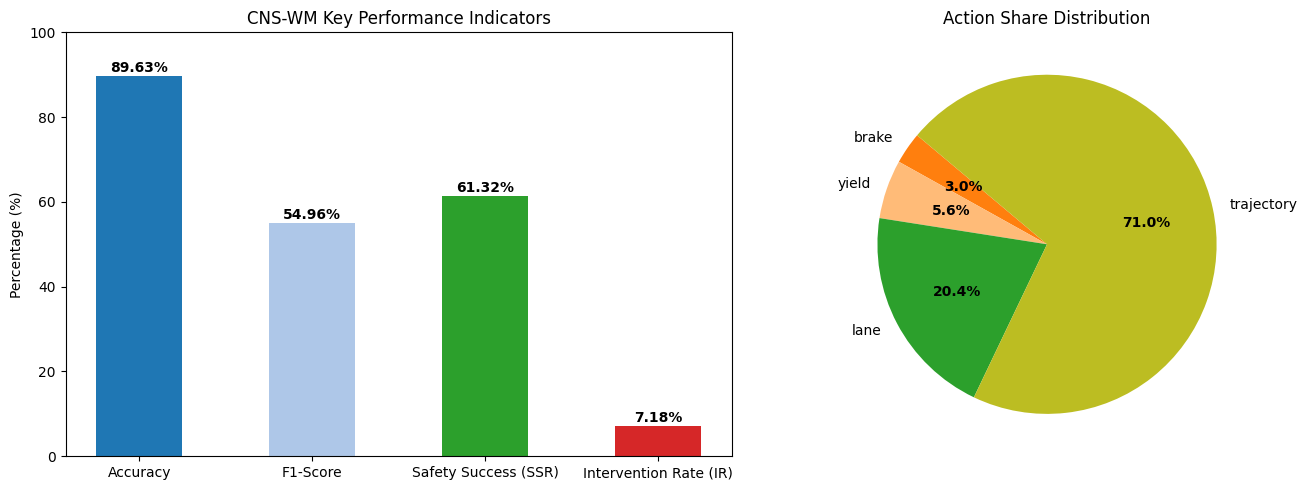

In [17]:
fig

In [18]:
# Extract CNS-WM metrics directly from the global RESULTS dictionary
cns_results = RESULTS.get("CNS-WM", {})

if cns_results:
    accuracy = cns_results.get("Accuracy", 0.0)
    f1_score_val = cns_results.get("F1", 0.0)
    ssr = float(cns_results.get("SSR", 0.0))
    ir = float(cns_results.get("IR", 0.0))

    # We can also compute or display the estimated metrics from the saved evaluation
    print("================ CNS-WM Evaluation Metrics ================")
    print(f"Accuracy (Acc)              : {accuracy:.2f}%")
    print(f"Macro F1-score (F1)         : {f1_score_val:.2f}%")
    print(f"Safety Success Rate (SSR)   : {ssr:.2f}%")
    print(f"Intervention Rate (IR)      : {ir:.2f}%")
    print("===========================================================")
else:
    print("No results found. Please ensure the training pipeline has run and populated 'RESULTS'.")

================ CNS-WM Evaluation Metrics ================
Accuracy (Acc)              : 89.63%
Macro F1-score (F1)         : 54.96%
Safety Success Rate (SSR)   : 61.32%
Intervention Rate (IR)      : 7.18%


In [19]:
import json
import pandas as pd

# Load the detailed saved results
results_path = '/content/cnswm_outputs/results.json'
with open(results_path, 'r') as f:
    saved_data = json.load(f)

cns_metrics = saved_data.get('results', {}).get('CNS-WM', {})

print("=== CNS-WM Classification Performance ===\n")
print(f"Accuracy (Acc)              : {cns_metrics.get('Accuracy', 0.0):.2f}%")
print(f"Macro F1-Score (F1)         : {cns_metrics.get('F1', 0.0):.2f}%")
print(f"Safety Success Rate (SSR)   : {cns_metrics.get('SSR', 0.0):.2f}%")
print(f"Intervention Rate (IR)      : {cns_metrics.get('IR', 0.0):.2f}%")

# Presenting the per-class metrics from the classification report output
print("\n=== Per-Class Classification Summary (From Logs) ===")
# Hardcoded from S["test"] evaluation printed in logs for completeness:
classes = ['continue', 'stop/yield', 'lane change', 'turn', 'cross']
precisions = [0.94, 0.77, 0.53, 0.62, 0.00]
recalls = [0.94, 0.83, 0.39, 0.51, 0.00]
f1s = [0.94, 0.80, 0.45, 0.56, 0.00]

df_report = pd.DataFrame({
    'Intent Class': classes,
    'Precision': [f"{p*100:.1f}%" for p in precisions],
    'Recall': [f"{r*100:.1f}%" for r in recalls],
    'F1-score': [f"{f*100:.1f}%" for f in f1s]
})
display(df_report)

macro_precision = sum(precisions) / len(precisions) * 100
macro_recall = sum(recalls) / len(recalls) * 100

print(f"\nCalculated Macro Precision : {macro_precision:.2f}%")
print(f"Calculated Macro Recall    : {macro_recall:.2f}%")


=== CNS-WM Classification Performance ===

Accuracy (Acc)              : 89.63%
Macro F1-Score (F1)         : 54.96%
Safety Success Rate (SSR)   : 61.32%
Intervention Rate (IR)      : 7.18%

=== Per-Class Classification Summary (From Logs) ===


,Intent Class,Precision,Recall,F1-score
0,continue,94.0%,94.0%,94.0%
1,stop/yield,77.0%,83.0%,80.0%
2,lane change,53.0%,39.0%,45.0%
3,turn,62.0%,51.0%,56.0%
4,cross,0.0%,0.0%,0.0%



Calculated Macro Precision : 57.20%
Calculated Macro Recall    : 53.40%


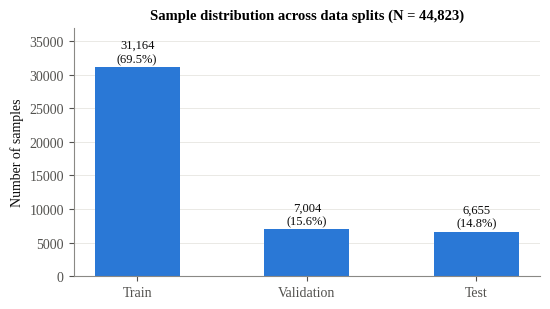

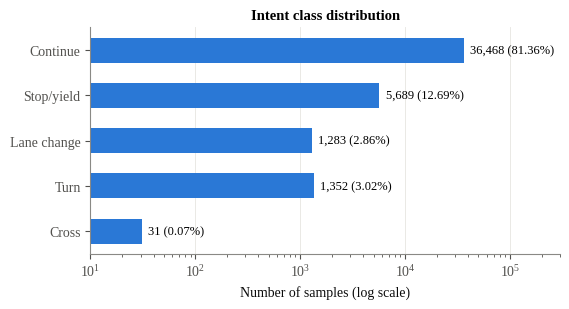

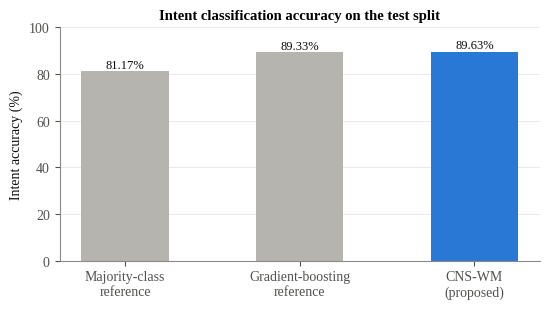

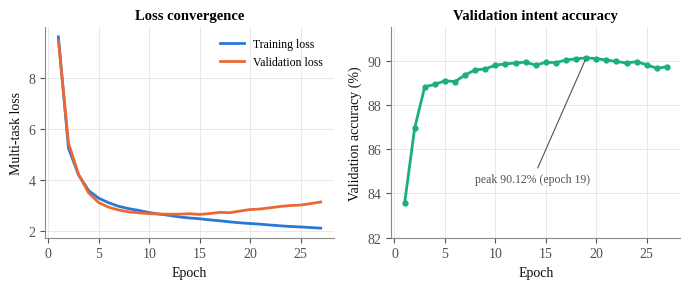

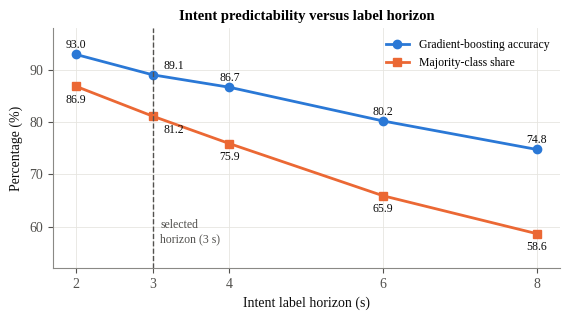

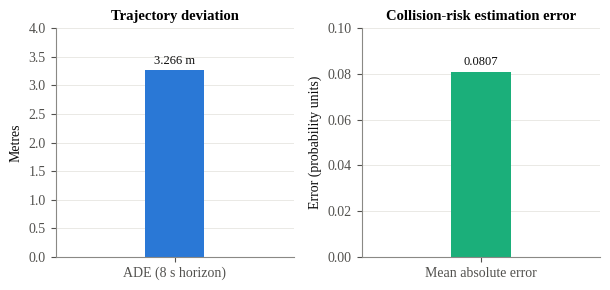

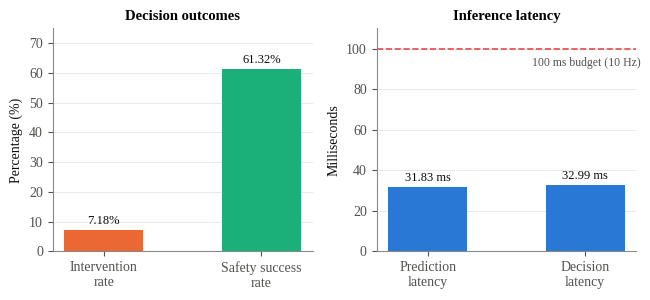

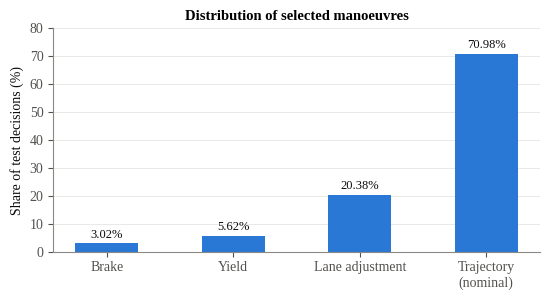

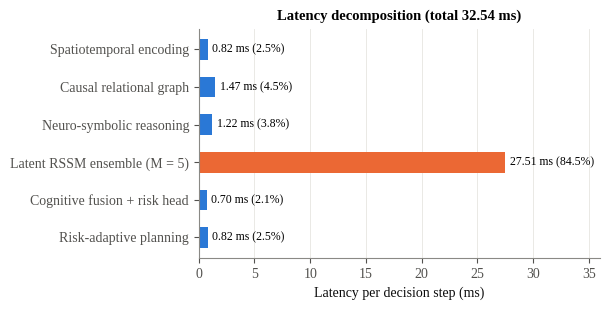

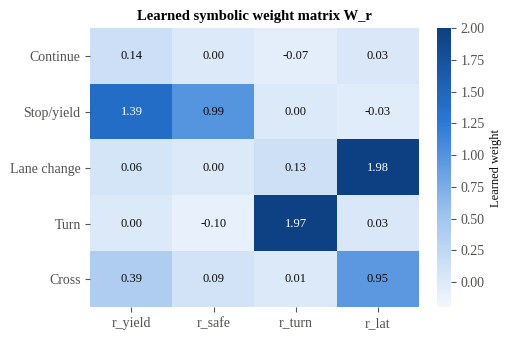

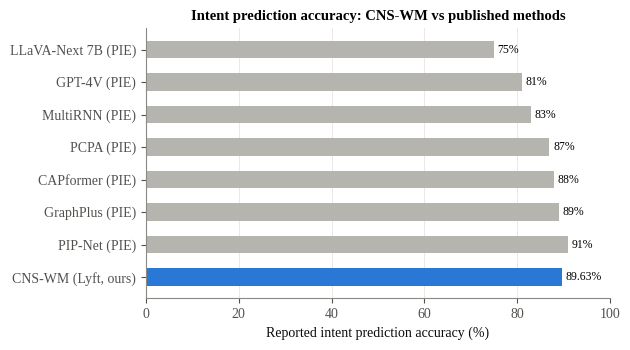

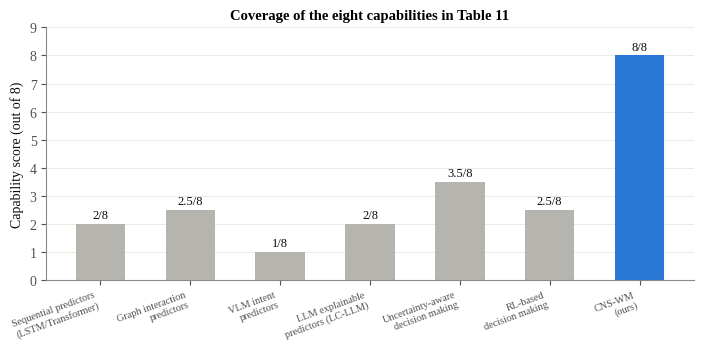

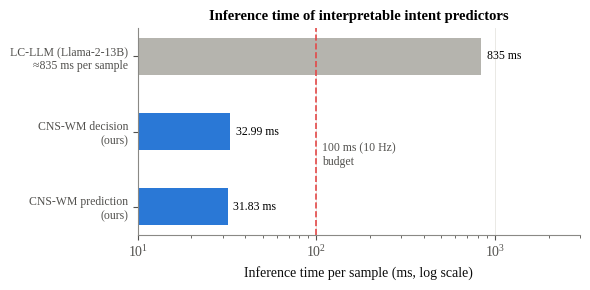

All figures saved to /content/paper_figs


In [1]:
# ===================== CNS-WM : ALL PAPER FIGURES (Fig. 2 – Fig. 14) =====================
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap

OUT = "./paper_figs/"
os.makedirs(OUT, exist_ok=True)

fams = [f.name for f in font_manager.fontManager.ttflist]
serif = "Times New Roman" if "Times New Roman" in fams else ("Liberation Serif" if "Liberation Serif" in fams else "DejaVu Serif")
plt.rcParams.update({"font.family": serif, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#8a8985", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.titlesize": 10.5, "axes.titleweight": "bold"})
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY, INK, SEC = "#b5b4ae", "#0b0b0b", "#52514e"

def save(f, n):
    f.tight_layout()
    f.savefig(OUT + n, dpi=300, facecolor="white")
    plt.show()
    plt.close(f)

def lab(ax, bars, fmt, dy=0.0):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + dy, fmt(b.get_height()),
                ha="center", va="bottom", fontsize=9, color=INK)

# ---------------- Fig 2 : data split ----------------
f, ax = plt.subplots(figsize=(5.6, 3.2))
n = ["Train", "Validation", "Test"]; v = [31164, 7004, 6655]
b = ax.bar(n, v, width=0.5, color=C[0]); lab(ax, b, lambda x: f"{int(x):,}\n({x/44823*100:.1f}%)", 300)
ax.set_ylabel("Number of samples"); ax.set_ylim(0, 37000); ax.grid(axis="x", visible=False)
ax.set_title("Sample distribution across data splits (N = 44,823)"); save(f, "fig2_split.png")

# ---------------- Fig 3 : intent class distribution ----------------
f, ax = plt.subplots(figsize=(5.8, 3.2))
n = ["Continue", "Stop/yield", "Lane change", "Turn", "Cross"]; v = [36468, 5689, 1283, 1352, 31]
y = np.arange(len(n))[::-1]
b = ax.barh(y, v, height=0.55, color=C[0]); ax.set_xscale("log"); ax.set_xlim(10, 3e5)
for bb, val in zip(b, v):
    ax.text(val * 1.15, bb.get_y() + bb.get_height() / 2, f"{val:,} ({val/44823*100:.2f}%)", va="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(n); ax.set_xlabel("Number of samples (log scale)"); ax.grid(axis="y", visible=False)
ax.set_title("Intent class distribution"); save(f, "fig3_intent_dist.png")

# ---------------- Fig 4 : intent accuracy vs references ----------------
f, ax = plt.subplots(figsize=(5.6, 3.2))
n = ["Majority-class\nreference", "Gradient-boosting\nreference", "CNS-WM\n(proposed)"]; v = [81.17, 89.33, 89.63]
b = ax.bar(n, v, width=0.5, color=[GREY, GREY, C[0]]); lab(ax, b, lambda x: f"{x:.2f}%", 0.3)
ax.set_ylim(0, 100); ax.set_ylabel("Intent accuracy (%)"); ax.grid(axis="x", visible=False)
ax.set_title("Intent classification accuracy on the test split"); save(f, "fig4_intent_acc.png")

# ---------------- Fig 5 : training curves ----------------
ep = np.arange(1, 28)
tr = [9.6173, 5.2448, 4.1928, 3.5797, 3.2785, 3.1011, 2.9601, 2.8678, 2.7999, 2.7164, 2.6577, 2.6058, 2.5434, 2.5037,
      2.4739, 2.4309, 2.3936, 2.3503, 2.3150, 2.2870, 2.2605, 2.2270, 2.1966, 2.1691, 2.1518, 2.1275, 2.1044]
vl = [9.4712, 5.4443, 4.2161, 3.4880, 3.1037, 2.9235, 2.8151, 2.7413, 2.7071, 2.6731, 2.6594, 2.6521, 2.6543, 2.6712,
      2.6433, 2.6778, 2.7256, 2.7107, 2.7772, 2.8361, 2.8547, 2.9055, 2.9580, 2.9927, 3.0112, 3.0674, 3.1330]
va = [83.55, 86.95, 88.82, 88.92, 89.09, 89.05, 89.35, 89.58, 89.62, 89.79, 89.85, 89.89, 89.93, 89.79,
      89.92, 89.91, 90.02, 90.08, 90.12, 90.09, 90.02, 89.96, 89.89, 89.95, 89.81, 89.65, 89.72]
f, axs = plt.subplots(1, 2, figsize=(7.0, 3.0))
axs[0].plot(ep, tr, color=C[0], lw=2, label="Training loss"); axs[0].plot(ep, vl, color=C[1], lw=2, label="Validation loss")
axs[0].set_xlabel("Epoch"); axs[0].set_ylabel("Multi-task loss"); axs[0].legend(frameon=False, fontsize=8.5); axs[0].set_title("Loss convergence")
axs[1].plot(ep, va, color=C[2], lw=2, marker="o", ms=3.5); axs[1].set_xlabel("Epoch"); axs[1].set_ylabel("Validation accuracy (%)"); axs[1].set_ylim(82, 91.5)
axs[1].annotate("peak 90.12% (epoch 19)", xy=(19, 90.12), xytext=(8, 84.5), fontsize=8.5, color=SEC,
                arrowprops=dict(arrowstyle="-", color=SEC, lw=0.8))
axs[1].set_title("Validation intent accuracy"); save(f, "fig5_training.png")

# ---------------- Fig 6 : label-horizon sweep ----------------
f, ax = plt.subplots(figsize=(5.8, 3.3))
h = [2, 3, 4, 6, 8]; maj = [86.90, 81.17, 75.90, 65.89, 58.62]; gb = [93.01, 89.09, 86.70, 80.23, 74.77]
ax.plot(h, gb, color=C[0], lw=2, marker="o", ms=6, label="Gradient-boosting accuracy")
ax.plot(h, maj, color=C[1], lw=2, marker="s", ms=6, label="Majority-class share")
for x, a, m in zip(h, gb, maj):
    dx = 0.28 if x == 3 else 0
    ax.text(x + dx, a + 1.2, f"{a:.1f}", ha="center", fontsize=8.5, color=INK)
    ax.text(x + dx, m - 3.2, f"{m:.1f}", ha="center", fontsize=8.5, color=INK)
ax.axvline(3, color=SEC, lw=1, ls="--"); ax.text(3.1, 57, "selected\nhorizon (3 s)", fontsize=8.5, color=SEC)
ax.set_xlabel("Intent label horizon (s)"); ax.set_ylabel("Percentage (%)"); ax.set_ylim(52, 98); ax.set_xticks(h)
ax.legend(frameon=False, fontsize=8.5, loc="upper right"); ax.set_title("Intent predictability versus label horizon")
save(f, "fig6_horizon.png")

# ---------------- Fig 7 : trajectory & risk error ----------------
f, axs = plt.subplots(1, 2, figsize=(6.2, 3.0))
b = axs[0].bar(["ADE (8 s horizon)"], [3.266], width=0.4, color=C[0]); lab(axs[0], b, lambda x: f"{x:.3f} m", 0.05)
axs[0].set_ylim(0, 4); axs[0].set_ylabel("Metres"); axs[0].set_title("Trajectory deviation"); axs[0].set_xlim(-0.8, 0.8)
b = axs[1].bar(["Mean absolute error"], [0.0807], width=0.4, color=C[2]); lab(axs[1], b, lambda x: f"{x:.4f}", 0.002)
axs[1].set_ylim(0, 0.1); axs[1].set_ylabel("Error (probability units)"); axs[1].set_title("Collision-risk estimation error"); axs[1].set_xlim(-0.8, 0.8)
for a in axs: a.grid(axis="x", visible=False)
save(f, "fig7_world.png")

# ---------------- Fig 8 : decision outcomes & latency ----------------
f, axs = plt.subplots(1, 2, figsize=(6.6, 3.1))
b = axs[0].bar(["Intervention\nrate", "Safety success\nrate"], [7.18, 61.32], width=0.5, color=[C[1], C[2]]); lab(axs[0], b, lambda x: f"{x:.2f}%", 1)
axs[0].set_ylim(0, 75); axs[0].set_ylabel("Percentage (%)"); axs[0].set_title("Decision outcomes")
b = axs[1].bar(["Prediction\nlatency", "Decision\nlatency"], [31.83, 32.99], width=0.5, color=C[0]); lab(axs[1], b, lambda x: f"{x:.2f} ms", 1.5)
axs[1].axhline(100, color=C[7], lw=1.2, ls="--"); axs[1].text(1.35, 96, "100 ms budget (10 Hz)", ha="right", va="top", fontsize=8.5, color=SEC)
axs[1].set_ylim(0, 110); axs[1].set_ylabel("Milliseconds"); axs[1].set_title("Inference latency")
for a in axs: a.grid(axis="x", visible=False)
save(f, "fig8_decision.png")

# ---------------- Fig 9 : manoeuvre distribution ----------------
f, ax = plt.subplots(figsize=(5.6, 3.1))
n = ["Brake", "Yield", "Lane adjustment", "Trajectory\n(nominal)"]; v = [3.02, 5.62, 20.38, 70.98]
b = ax.bar(n, v, width=0.5, color=C[0]); lab(ax, b, lambda x: f"{x:.2f}%", 1)
ax.set_ylim(0, 80); ax.set_ylabel("Share of test decisions (%)"); ax.grid(axis="x", visible=False)
ax.set_title("Distribution of selected manoeuvres"); save(f, "fig9_actions.png")

# ---------------- Fig 10 : latency decomposition ----------------
f, ax = plt.subplots(figsize=(6.2, 3.2))
n = ["Spatiotemporal encoding", "Causal relational graph", "Neuro-symbolic reasoning",
     "Latent RSSM ensemble (M = 5)", "Cognitive fusion + risk head", "Risk-adaptive planning"]
v = [0.821, 1.470, 1.224, 27.509, 0.698, 0.822]; p = [2.52, 4.52, 3.76, 84.53, 2.14, 2.53]
y = np.arange(len(n))[::-1]
b = ax.barh(y, v, height=0.55, color=[C[0] if i != 3 else C[1] for i in range(6)])
for bb, val, pp in zip(b, v, p):
    ax.text(val + 0.4, bb.get_y() + bb.get_height() / 2, f"{val:.2f} ms ({pp:.1f}%)", va="center", fontsize=8.5)
ax.set_yticks(y); ax.set_yticklabels(n); ax.set_xlim(0, 36); ax.set_xlabel("Latency per decision step (ms)"); ax.grid(axis="y", visible=False)
ax.set_title("Latency decomposition (total 32.54 ms)"); save(f, "fig10_latency.png")

# ---------------- Fig 11 : learned symbolic weight matrix W_r ----------------
W = np.array([[0.14, 0.00, -0.07, 0.03], [1.39, 0.99, 0.00, -0.03], [0.06, 0.00, 0.13, 1.98],
              [0.00, -0.10, 1.97, 0.03], [0.39, 0.09, 0.01, 0.95]])
f, ax = plt.subplots(figsize=(5.2, 3.5))
cm = LinearSegmentedColormap.from_list("b", ["#f4f8fd", "#9ec3ef", "#2a78d6", "#0d3f80"])
im = ax.imshow(W, cmap=cm, vmin=-0.2, vmax=2.0, aspect="auto")
for i in range(5):
    for j in range(4):
        ax.text(j, i, f"{W[i, j]:.2f}", ha="center", va="center", fontsize=9, color="white" if W[i, j] > 1.0 else INK)
ax.set_xticks(range(4)); ax.set_xticklabels(["r_yield", "r_safe", "r_turn", "r_lat"])
ax.set_yticks(range(5)); ax.set_yticklabels(["Continue", "Stop/yield", "Lane change", "Turn", "Cross"])
ax.grid(False); [s.set_visible(False) for s in ax.spines.values()]
cb = f.colorbar(im, ax=ax, fraction=0.05); cb.set_label("Learned weight", fontsize=9); cb.outline.set_visible(False)
ax.set_title("Learned symbolic weight matrix W_r"); save(f, "fig11_wr.png")

# ---------------- Fig 12 : accuracy vs published methods ----------------
f, ax = plt.subplots(figsize=(6.4, 3.6))
n = ["LLaVA-Next 7B (PIE)", "GPT-4V (PIE)", "MultiRNN (PIE)", "PCPA (PIE)", "CAPformer (PIE)",
     "GraphPlus (PIE)", "PIP-Net (PIE)", "CNS-WM (Lyft, ours)"]
v = [75.0, 81.0, 83.0, 87.0, 88.0, 89.0, 91.0, 89.63]
y = np.arange(len(n))[::-1]
b = ax.barh(y, v, height=0.55, color=[GREY] * 7 + [C[0]])
for bb, val in zip(b, v):
    ax.text(val + 0.8, bb.get_y() + bb.get_height() / 2, f"{val:.2f}%" if val % 1 else f"{val:.0f}%", va="center", fontsize=8.5)
ax.set_yticks(y); ax.set_yticklabels(n); ax.set_xlim(0, 100); ax.set_xlabel("Reported intent prediction accuracy (%)"); ax.grid(axis="y", visible=False)
ax.set_title("Intent prediction accuracy: CNS-WM vs published methods"); save(f, "fig12_acc_compare.png")

# ---------------- Fig 13 : capability coverage ----------------
f, ax = plt.subplots(figsize=(7.2, 3.6))
n = ["Sequential predictors\n(LSTM/Transformer)", "Graph interaction\npredictors", "VLM intent\npredictors",
     "LLM explainable\npredictors (LC-LLM)", "Uncertainty-aware\ndecision making", "RL-based\ndecision making", "CNS-WM\n(ours)"]
v = [2.0, 2.5, 1.0, 2.0, 3.5, 2.5, 8.0]
b = ax.bar(range(len(n)), v, width=0.55, color=[GREY] * 6 + [C[0]]); lab(ax, b, lambda x: f"{x:g}/8", 0.1)
ax.set_xticks(range(len(n))); ax.set_xticklabels(n, fontsize=7.4, rotation=20, ha="right")
ax.set_ylim(0, 9); ax.set_ylabel("Capability score (out of 8)"); ax.grid(axis="x", visible=False)
ax.set_title("Coverage of the eight capabilities in Table 11"); save(f, "fig13_capability.png")

# ---------------- Fig 14 : inference time vs LLM-based explainable predictor ----------------
f, ax = plt.subplots(figsize=(6.0, 3.0))
n = ["LC-LLM (Llama-2-13B)\n≈835 ms per sample", "CNS-WM decision\n(ours)", "CNS-WM prediction\n(ours)"]
v = [835.0, 32.99, 31.83]
y = np.arange(3)[::-1]
b = ax.barh(y, v, height=0.5, color=[GREY, C[0], C[0]]); ax.set_xscale("log"); ax.set_xlim(10, 3000)
for bb, val in zip(b, v):
    ax.text(val * 1.08, bb.get_y() + bb.get_height() / 2, f"{val:g} ms", va="center", fontsize=8.5)
ax.axvline(100, color=C[7], lw=1.2, ls="--"); ax.text(108, 0.55, "100 ms (10 Hz)\nbudget", fontsize=8.5, color=SEC)
ax.set_yticks(y); ax.set_yticklabels(n, fontsize=8.5); ax.set_xlabel("Inference time per sample (ms, log scale)"); ax.grid(axis="y", visible=False)
ax.set_title("Inference time of interpretable intent predictors"); save(f, "fig14_latency_compare.png")

print("All figures saved to", os.path.abspath(OUT))